<a href="https://colab.research.google.com/github/julia-iza/Trabajo-Practico-Laboratorio/blob/main/analisis_subte.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **🚅 Análisis del Subte de Buenos Aires**



In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# **1- Carga y exploración**

Cargamos los archivos procesados de viajes en subte correspondientes a los años 2015 a 2026. El objetivo es reunir información suficiente para estudiar la evolución de la demanda y comparar los patrones de viaje a lo largo del tiempo. El año 2026 puede contener datos parciales, por lo que se analizará teniendo en cuenta su cobertura temporal.

## *Carga y unificación de los datos*
En esta sección cargamos los archivos procesados de viajes en subte correspondientes a los años 2015–2026 desde el repositorio de GitHub. Convertimos la columna fecha a un formato de fecha y agregamos una columna con el año de cada registro. Luego, unificamos los archivos en un único DataFrame llamado df.

Esta operación permite trabajar con los datos de distintos años en una misma tabla y facilita la comparación de la demanda a lo largo del tiempo, así como la elaboración de visualizaciones para responder la pregunta de investigación.

In [ ]:
anios = range(2015, 2027)
bases = []

for anio in anios:
    url = (
        "https://raw.githubusercontent.com/"
        "julia-iza/Trabajo-Practico-Laboratorio/main/"
        f"data/processed/por_anio/molinetes_{anio}.csv.gz"         #tarea asistida por IA, se le pidio la realizacion del codigo para cargar y unificar los archivos procesados de viajes de subte de los años 2015-2026

    )

    try:
        df_anio = pd.read_csv(url, compression="gzip")
        df_anio["fecha"] = pd.to_datetime(df_anio["fecha"])
        df_anio["anio"] = anio

        bases.append(df_anio)
        print(f"{anio}: {len(df_anio):,} filas cargadas")

    except Exception as e:
        print(f"{anio}: no se pudo cargar. Error: {e}")

df = pd.concat(bases, ignore_index=True)

print("\nTotal de filas:", f"{len(df):,}")
print("\nAños cargados:", sorted(df["anio"].unique()))

df.head()


2015: 522,807 filas cargadas
2016: 545,897 filas cargadas
2017: 547,713 filas cargadas
2018: 561,732 filas cargadas
2019: 589,004 filas cargadas
2020: 359,496 filas cargadas
2021: 426,415 filas cargadas
2022: 597,791 filas cargadas
2023: 583,852 filas cargadas
2024: 579,277 filas cargadas
2025: 585,316 filas cargadas
2026: 397,591 filas cargadas

Total de filas: 6,296,891

Años cargados: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]


,fecha,hora,linea,estacion,pax_pagos,pax_pases_pagos,pax_franq,total,anio
0,2015-01-01,5,LineaA,PLAZA MISERERE,0,0,0,0,2015
1,2015-01-01,5,LineaD,CATEDRAL,0,0,0,0,2015
2,2015-01-01,5,LineaD,CONGRESO DE TUCUMAN,0,0,0,0,2015
3,2015-01-01,5,LineaH,CASEROS,0,0,0,0,2015
4,2015-01-01,6,LineaC,INDEPENDENCIA,0,0,0,0,2015


##*Limpieza de los nombres de las estaciones*

**Qué problema se encontró.** Al analizar los datos por estación, algunas estaciones aparecían con más de un nombre. Por ejemplo, la estación Sáenz Peña figuraba como `SAENZ PENA`, `SAENZ PE±A`, `SAENZ PE¤A` y `SAENZ PE�A`, y Agüero como `AGUERO`, `AG3ERO`, `AG\x81ERO` y `AG�ERO`. La causa son errores de codificación de caracteres en algunos archivos originales (letras como la ñ y la ü que se guardaron mal). Como el código toma cada nombre distinto como una estación distinta, no podía comparar 2019 con 2024-2025 para esas estaciones y devolvía valores vacíos (`NaN`). Se le pidío a la **IA** que corriga estos errores.

**Qué se hizo.**
1. **Primera función (`limpiar_nombre`):** intenta corregir el texto mal codificado, pasa los nombres a mayúsculas y elimina las tildes, de modo que todos los nombres sigan el mismo formato.
2. **Segunda función (`canonico`):** unifica las variantes que la primera no pudo corregir (las que tenían caracteres irrecuperables) usando patrones de texto: toda variante de "AGÜERO" pasa a `AGUERO` y toda variante de "SÁENZ PEÑA" pasa a `SAENZ PENA`. También se unificó `RETIRO E` con `RETIRO`, ya que corresponde a la estación Retiro de la línea E.
3. **Control:** se imprimen los nombres que todavía contienen caracteres que no son letras ni números. Solo quedó `#N/D`, que no es una estación.

**Valores inválidos que quedaron.**
- `#N/D` (el error "no disponible" de Excel) aparece en 7 filas de la línea H, con 9 pasajeros en total. Es una cantidad insignificante frente a los más de 200 millones de pasajeros por año, por lo que no se eliminó y no afecta los resultados.
- `COCHEPM` pertenece a la línea Premetro (PM), que se excluye de todos los análisis, por lo que nunca entra en los cálculos.

**Qué análisis afecta.** Esta limpieza solo modifica la columna de estaciones. Los totales por año, línea, hora y día de la semana no cambian, porque no dependen del nombre de la estación. Solo influye en el gráfico de estaciones, que ahora compara cada estación consigo misma entre 2019 y 2024-2025.

In [ ]:
import unicodedata

def limpiar_nombre(s):
    # Corrige errores de codificación (por ejemplo, "PEÃÂ±A") y quita tildes
    for _ in range(2):
        try:
            s = s.encode("latin-1").decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            break
    s = unicodedata.normalize("NFKD", s)
    return "".join(c for c in s if not unicodedata.combining(c)).upper().strip()

nombres = {n: limpiar_nombre(n) for n in df["estacion"].unique()}
df["estacion"] = df["estacion"].map(nombres)

print(sorted(df["estacion"].unique()))  # para revisar que no queden nombres raros

['9 DE JULIO', 'ACOYTE', 'AGUERO', 'ALBERTI', 'ANGEL GALLARDO', 'AVENIDA DE MAYO', 'AVENIDA LA PLATA', 'BOEDO', 'BOLIVAR', 'BULNES', 'CALLAO', 'CARABOBO', 'CARLOS GARDEL', 'CARLOS PELLEGRINI', 'CASEROS', 'CASTRO BARROS', 'CATALINAS', 'CATEDRAL', 'COCHEPM', 'CONGRESO', 'CONGRESO DE TUCUMAN', 'CONSTITUCION', 'CORDOBA', 'CORREO CENTRAL', 'CORRIENTES', 'DIAGONAL NORTE', 'DORREGO', 'ECHEVERRIA', 'EMILIO MITRE', 'ENTRE RIOS', 'FACULTAD DE DERECHO', 'FACULTAD DE MEDICINA', 'FEDERICO LACROZE', 'FLORES', 'FLORIDA', 'GENERAL BELGRANO', 'GENERAL SAN MARTIN', 'HOSPITALES', 'HUMBERTO I', 'INCLAN', 'INDEPENDENCIA', 'JOSE HERNANDEZ', 'JOSE MARIA MORENO', 'JUJUY', 'JURAMENTO', 'LAS HERAS', 'LAVALLE', 'LEANDRO N ALEM', 'LIMA', 'LORIA', 'LOS INCAS', 'MALABIA', 'MARIANO MORENO', 'MEDALLA MILAGROSA', 'MEDRANO', 'MINISTRO CARRANZA', 'ND', 'OLLEROS', 'ONCE', 'PALERMO', 'PASCO', 'PASTEUR', 'PATRICIOS', 'PERU', 'PICHINCHA', 'PIEDRAS', 'PLAZA DE MAYO', 'PLAZA ITALIA', 'PLAZA MISERERE', 'PRIMERA JUNTA', 'PUAN',

In [ ]:
import re

def canonico(n):
    # Unifica las variantes con caracteres rotos
    if re.fullmatch(r"AG.ERO", n):
        return "AGUERO"
    if re.fullmatch(r"SAENZ PE.A", n):
        return "SAENZ PENA"
    if n == "RETIRO E":
        return "RETIRO"
    return n

df["estacion"] = df["estacion"].map(canonico)

# Control: nombres que todavía tengan caracteres raros
print([n for n in df["estacion"].unique() if not re.fullmatch(r"[A-Z0-9 ]+", n)])

[]


In [ ]:
# Filas con nombres de estación inválidos (#N/D y COCHEPM)
sub = df[df["estacion"].isin(["#N/D", "COCHEPM"])]
print(sub.groupby(["anio", "linea", "estacion"])["total"].agg(["size", "sum"]))

                       size     sum
anio linea   estacion              
2025 LineaPM COCHEPM    957   43880
2026 LineaPM COCHEPM   2626  757844


In [ ]:
df.tail()

,fecha,hora,linea,estacion,pax_pagos,pax_pases_pagos,pax_franq,total,anio
6296886,2026-08-31,23,LineaH,LAS HERAS,13,0,1,14,2026
6296887,2026-08-31,23,LineaH,ONCE,9,0,2,11,2026
6296888,2026-08-31,23,LineaH,PATRICIOS,8,0,1,9,2026
6296889,2026-08-31,23,LineaH,SANTA FE,12,0,5,17,2026
6296890,2026-08-31,23,LineaH,VENEZUELA,11,0,11,22,2026


---

# ***2- Pregunta de investigación***

##Recuperó el subte de Buenos Aires la demanda previa a la pandemia? ¿Cómo cambió cuándo (hora y día) y dónde (estación y línea) se viaja?

##***2.1 ¿Por qué vale la pena responderla?***

**1. Sirve para planificar el servicio.** La cantidad de pasajeros, y cuándo y dónde viajan, influye en decisiones como cuántas formaciones poner y en qué horarios, qué estaciones requieren inversión y cuánto cuesta sostener el sistema. Este trabajo encuentra que la demanda actual ronda el 60 % de la de 2019, por lo que conviene verificar si una planificación basada en los patrones previos a la pandemia sigue siendo adecuada.

**2. Aporta datos a una discusión actual.** El subte porteño tuvo aumentos de tarifa importantes desde 2024, y la discusión sobre cuánto cobrar y quién financia el servicio depende en parte de cuánta gente lo usa. Los datos permiten mirar la evolución de la demanda con números y no con impresiones. Este trabajo describe qué ocurrió, pero no mide el efecto de las tarifas ni de otros factores sobre la demanda.

**3. Muestra si cambió la forma de moverse en la ciudad.** Que la demanda se recupere o no, y en qué horarios, días y zonas, ayuda a entender si los hábitos de trabajo, estudio y traslado cambiaron de forma duradera después de la pandemia. Por eso el análisis no se limita al total anual, sino que mira también *cuándo* (hora y día) y *dónde* (línea y estación) se viaja.

**4. Es una pregunta que los datos pueden responder.** El dataset reúne más de diez años de registros por molinete, con fecha, hora, línea y estación, lo que permite comparar un período previo y uno posterior a la pandemia con las mismas variables.

# ***2.2 ¿Que respuesta encontramos?***


**¿Recuperó el subte la demanda previa a la pandemia?** No. En 2019 se registraron 341,3 millones de pasajeros, en 2020 la cifra cayó a 77,5 millones (77 % menos) y la recuperación alcanzó su máximo en 2023 (71,3 % de 2019). En 2024 y 2025 la demanda quedó en torno al 60 % del nivel de 2019 (59,0 % y 60,5 %).

**¿Cuándo se viaja?** La distribución horaria casi no cambió entre 2019 y 2024-2025: los picos siguen a las 8 h y a las 17 h, y ninguna hora varió su participación en más de 1 punto porcentual, aunque las horas pico ganaron algo de peso frente al mediodía y la noche. Todos los días de la semana perdieron pasajeros, pero la caída fue mayor de lunes a viernes (entre 37,6 % y 45,1 %) que el fin de semana (entre 29,5 % y 32,4 %), por lo que los días hábiles pasaron de representar el 88,7 % al 86,9 % de los pasajeros de la semana.

**¿Dónde se viaja?** La recuperación fue despareja entre líneas, de 48,4 % en la línea D a 85,1 % en la línea E (78,8 % si se excluyen las tres estaciones inauguradas en 2019). Las líneas B y D, las más usadas, concentran cerca del 58 % de la pérdida total. A nivel de estación, Constitución sigue siendo la más usada por amplio margen y las 10 principales concentran la misma proporción del total (30,4 % y 30,0 %), pero algunas estaciones del centro y de la línea D recuperaron mucho menos que el resto (por ejemplo, 9 de Julio con 31,6 % y Agüero con 39,1 %).

**En conjunto,** la demanda del subte se estabilizó alrededor del 60 % de la de 2019, pero su patrón de uso cambió poco en su forma: se viaja en las mismas horas, en los mismos días y en las mismas estaciones principales, con una pérdida algo mayor en los días hábiles, en las líneas más cargadas y en estaciones del centro.

**Qué no se puede concluir.** Los datos describen qué ocurrió, pero no permiten medir por qué. Diversos informes señalan al trabajo remoto o híbrido y a los aumentos de tarifa desde 2024 como posibles factores, pero este análisis no mide cuánto aporta cada uno.

**Limitaciones.**
- Las variables cuentan ingresos por los molinetes, no personas distintas.
- Desde diciembre de 2024 se habilitó el pago con tarjetas y celular, y los archivos incluyen "otros modos de pago" en su nombre; no se pudo confirmar en la documentación si esos pasajeros se suman al total, por lo que 2025 es el año con más incertidumbre. La serie mensual no muestra un quiebre en esa fecha.
- Se excluyó el Premetro, que aparece en los datos recién desde junio de 2025.
- Las fechas de 2020 y 2021 se reconstruyeron por inferencia, por lo que el detalle mensual de esos años es menos confiable.
- Algunos meses tienen menos registros que el resto (enero y febrero de 2024), y hay errores puntuales en los datos originales, de cantidad insignificante.
- Las comparaciones por línea y estación no verifican cambios en la red salvo la ampliación de la línea E de 2019.

---

#**3- Transformaciones y resumen estadístico**





##**Transformaciones: Columnas derivadas de la fecha**

1. **Conversión de tipos.** La columna `fecha` viene como texto en los archivos procesados y se convierte a `datetime` al cargarlos (celda de carga). Sin esa conversión no se podría extraer el año, el mes ni el día de la semana, ni ordenar o filtrar los registros por fecha.
2. **Columnas derivadas.** A partir de la fecha se crean columnas que sirven para agrupar:
   * `anio` (creada al cargar los archivos) y `mes`;
   * `periodo`: año y mes juntos (por ejemplo, `2019-04`), para series mensuales;
   * `dia_semana`: 0 = lunes … 6 = domingo, y `nombre_dia` con el nombre;
   * `tipo_dia`: "hábil" de lunes a viernes y "fin de semana" sábado y domingo. No distingue feriados: un feriado que cae un martes cuenta como hábil.

**Por qué.** La pregunta de investigación compara la demanda entre años, meses, días de la semana y días hábiles contra fines de semana. Tener estas columnas permite agrupar directamente con `groupby` en lugar de recalcular la fecha en cada gráfico, y hace que todos los análisis usen la misma definición de, por ejemplo, "día hábil".

In [ ]:
NOMBRES_DIAS = {0: "lunes", 1: "martes", 2: "miércoles", 3: "jueves",
                4: "viernes", 5: "sábado", 6: "domingo"}

df["mes"] = df["fecha"].dt.month
df["periodo"] = df["fecha"].dt.to_period("M")
df["dia_semana"] = df["fecha"].dt.dayofweek
df["nombre_dia"] = df["dia_semana"].apply(lambda d: NOMBRES_DIAS[d])
df["tipo_dia"] = df["dia_semana"].apply(lambda d: "hábil" if d < 5 else "fin de semana")

df[["fecha", "anio", "mes", "periodo", "dia_semana", "nombre_dia", "tipo_dia"]].head()

,fecha,anio,mes,periodo,dia_semana,nombre_dia,tipo_dia
0,2015-01-01,2015,1,2015-01,3,jueves,hábil
1,2015-01-01,2015,1,2015-01,3,jueves,hábil
2,2015-01-01,2015,1,2015-01,3,jueves,hábil
3,2015-01-01,2015,1,2015-01,3,jueves,hábil
4,2015-01-01,2015,1,2015-01,3,jueves,hábil


####*Verificación*

Antes de construir las visualizaciones, verificamos que los datos se hayan cargado correctamente. Observamos las primeras filas del DataFrame y comprobamos qué años están disponibles y cuántos registros contiene cada uno. Esto nos permite conocer la estructura de los datos y detectar posibles problemas antes de continuar con el análisis.

In [ ]:
print("Dimensiones de la tabla:", df.shape)

print("\nAños disponibles:")
print(sorted(df["anio"].unique()))

print("\nCantidad de registros por año:")
print(df.groupby("anio").size())

print("\nPrimeras filas:")
display(df.head())


Dimensiones de la tabla: (6296891, 14)

Años disponibles:
[np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]

Cantidad de registros por año:
anio
2015    522807
2016    545897
2017    547713
2018    561732
2019    589004
2020    359496
2021    426415
2022    597791
2023    583852
2024    579277
2025    585316
2026    397591
dtype: int64

Primeras filas:


,fecha,hora,linea,estacion,pax_pagos,pax_pases_pagos,pax_franq,total,anio,mes,periodo,dia_semana,nombre_dia,tipo_dia
0,2015-01-01,5,LineaA,PLAZA MISERERE,0,0,0,0,2015,1,2015-01,3,jueves,hábil
1,2015-01-01,5,LineaD,CATEDRAL,0,0,0,0,2015,1,2015-01,3,jueves,hábil
2,2015-01-01,5,LineaD,CONGRESO DE TUCUMAN,0,0,0,0,2015,1,2015-01,3,jueves,hábil
3,2015-01-01,5,LineaH,CASEROS,0,0,0,0,2015,1,2015-01,3,jueves,hábil
4,2015-01-01,6,LineaC,INDEPENDENCIA,0,0,0,0,2015,1,2015-01,3,jueves,hábil


##**Estadísticos**


❕Al analizarlos hay que tener en cuenta las limitaciones que contienen los datasets por ejemplo el nuevo teletrabajo o el aumento de tarifas.

###*1- Comparación de pasajeros entre 2015/19 y últimos 12 meses*

In [ ]:
import pandas as pd

# Filtramos las líneas principales (A-H)
lineas = ["LineaA", "LineaB", "LineaC", "LineaD", "LineaE", "LineaH"]
df_sub = df[df["linea"].isin(lineas)].copy()

# Identificamos los meses disponibles de 2026 (1 al 8)
# Para completar 12 meses, necesitamos 4 meses de 2025 (9 al 12)
condicion_ultimos_12 = (
    ((df_sub["anio"] == 2026) & (df_sub["mes"] <= 8)) |
    ((df_sub["anio"] == 2025) & (df_sub["mes"] >= 9))
)

# Creamos un dataset especial para los últimos 12 meses etiquetándolos en un grupo común
df_ultimos_12 = df_sub[condicion_ultimos_12].copy()

# Agrupamos por fecha para obtener los pasajeros totales del sistema por día para los años históricos
pasajeros_por_dia_hist = df_sub[df_sub["anio"].isin([2015, 2016, 2017, 2018, 2019])].groupby(["anio", "fecha"])["total"].sum().reset_index()
resumen_anual = pasajeros_por_dia_hist.groupby("anio")["total"].agg(["mean", "median"]
)
resumen_anual.columns = ["Promedio Diario (Pasajeros)", "Mediana Diaria (Pasajeros)"]
resumen_anual.index.name = "Año"

# Calculamos los estadísticos para el bloque de Últimos 12 meses agrupando por fecha
pasajeros_por_dia_u12 = df_ultimos_12.groupby("fecha")["total"].sum().reset_index()
promedio_u12 = pasajeros_por_dia_u12["total"].mean()
mediana_u12 = pasajeros_por_dia_u12["total"].median()

# Armamos la tabla comparativa final
tabla_comparativa = resumen_anual.copy()
tabla_comparativa.loc["Últimos 12 meses (2025+2026)"] = [promedio_u12, mediana_u12]
tabla_comparativa = tabla_comparativa.round(1)

print("Estadísticos de resumen diario del sistema de Subte:")
display(tabla_comparativa)

# Cálculo de variaciones porcentuales respecto a 2019
prom_2019 = tabla_comparativa.loc[2019, "Promedio Diario (Pasajeros)"]
prom_u12 = tabla_comparativa.loc["Últimos 12 meses (2025+2026)", "Promedio Diario (Pasajeros)"]
var_prom_19_u12 = ((prom_u12 / prom_2019) - 1) * 100

med_2019 = tabla_comparativa.loc[2019, "Mediana Diaria (Pasajeros)"]
med_u12 = tabla_comparativa.loc["Últimos 12 meses (2025+2026)", "Mediana Diaria (Pasajeros)"]
var_med_19_u12 = ((med_u12 / med_2019) - 1) * 100

print(f"\nVariación del Promedio Diario (Últimos 12 meses vs. 2019): {var_prom_19_u12:.1f}%")
print(f"Variación de la Mediana Diaria (Últimos 12 meses vs. 2019): {var_med_19_u12:.1f}%")

Estadísticos de resumen diario del sistema de Subte:


,Promedio Diario (Pasajeros),Mediana Diaria (Pasajeros)
Año,,
2015,774025.0,988216.0
2016,859066.1,1066520.5
2017,900552.7,1143302.0
2018,954520.9,1183530.0
2019,942929.6,1186703.0
Últimos 12 meses (2025+2026),561025.6,680605.0



Variación del Promedio Diario (Últimos 12 meses vs. 2019): -40.5%
Variación de la Mediana Diaria (Últimos 12 meses vs. 2019): -42.6%


📊 Interpretación

Ambos estadisticos nos brindan la misma información: la cantidad de pasajeros cayó drasticamente al pasar de los años

- Promedio Diario de Pasajeros:

Pre-pandemia: Durante 2018 y 2019, el subte transportaba un promedio diario de 954,520.9 y 942,929.6 pasajeros respectivamente.
Mientras que en la actualidad: En el último año registrado, el promedio diario descendió a 561025,6 pasajeros.
Esto representa una caída del -40.5% en el promedio diario en comparación con 2019.

- Mediana Diaria de Pasajeros:

Pre-pandemia: La mitad de los días del año se superaban los 1,183,530 (2018) y 1,186,703 (2019) pasajeros diarios.
Actualidad (2026): La mediana se posiciona actualmente en 680,605 pasajeros.
Variación: Esto equivale a una reducción del -42.6% en la mediana diaria respecto al año 2019.


⏰Ahora analicemos la demanda según los horarios:

###*2- Demanda en hora pico de la tarde (17.00hs) a lo largo de los años*

In [ ]:
import pandas as pd

# Filtramos las líneas principales (A-H)
lineas = ["LineaA", "LineaB", "LineaC", "LineaD", "LineaE", "LineaH"]
df_sub = df[df["linea"].isin(lineas)].copy()

# Filtramos por el horario pico de la tarde (17 h)
df_pico_tarde = df_sub[df_sub["hora"] == 17].copy()

# --- 1) Tabla de Estadísticos Históricos (Años Individuales) ---
# Agrupamos por año y fecha para obtener el total diario a las 17 h
pasajeros_pico_dia = (
    df_pico_tarde.groupby(["anio", "fecha"])[["total"]].sum().reset_index()
)

# Calculamos el promedio y la mediana diaria para las 17 h por año
resumen_pico_tarde = pasajeros_pico_dia.groupby("anio")["total"].agg(["mean", "median"]
)
resumen_pico_tarde.columns = ["Promedio en Hora Pico 17h", "Mediana en Hora Pico 17h"]
resumen_pico_tarde.index.name = "Año"

# Renombramos el índice 2026 para que se muestre como 'Enero-agosto 2026'
resumen_pico_tarde = resumen_pico_tarde.rename(index={2026: "Enero-agosto 2026"})

# --- 2) Cálculo de los Estadísticos de los Últimos 12 Meses Reales (Sep 2025 - Ago 2026) ---
condicion_u12 = (
    ((df_pico_tarde["anio"] == 2026) & (df_pico_tarde["mes"] <= 8)) |
    ((df_pico_tarde["anio"] == 2025) & (df_pico_tarde["mes"] >= 9))
)
df_pico_u12 = df_pico_tarde[condicion_u12].copy()

# Agrupamos por fecha para obtener los estadísticos de este bloque de 12 meses móviles
pasajeros_pico_u12 = df_pico_u12.groupby("fecha")[["total"]].sum().reset_index()
prom_u12_pico = pasajeros_pico_u12["total"].mean()
med_u12_pico = pasajeros_pico_u12["total"].median()

# --- 3) Agregar la fila final a la tabla explicativa ---
tabla_final_pico = resumen_pico_tarde.copy()
tabla_final_pico.loc["Últimos 12 meses (2025+2026)"] = [prom_u12_pico, med_u12_pico]

print("Estadísticos de la Hora Pico de la Tarde (17 h) por año:")
display(tabla_final_pico.round(1))

# Valores de referencia de 2019
prom_19_pico = resumen_pico_tarde.loc[2019, "Promedio en Hora Pico 17h"]
med_19_pico = resumen_pico_tarde.loc[2019, "Mediana en Hora Pico 17h"]

# Variaciones porcentuales
var_prom_pico = ((prom_u12_pico / prom_19_pico) - 1) * 100
var_med_pico = ((med_u12_pico / med_19_pico) - 1) * 100

print(
    f"\nVariación del promedio en hora pico de la tarde (Últimos 12 meses vs. 2019): {var_prom_pico:.1f}%"
)
print(
    f"Variación de la mediana en hora pico de la tarde (Últimos 12 meses vs. 2019): {var_med_pico:.1f}%"
)
print(
    "\nNota: Las variaciones porcentuales se calcularon utilizando la ventana real de los últimos 12 meses "
    "disponibles (septiembre 2025 a agosto 2026) en comparación con el año completo 2019 para mantener la consistencia metodológica."
)

Estadísticos de la Hora Pico de la Tarde (17 h) por año:


,Promedio en Hora Pico 17h,Mediana en Hora Pico 17h
Año,,
2015,69767.4,90121.5
2016,76579.7,95697.0
2017,79933.1,104492.0
2018,83804.1,107740.0
2019,82881.6,105374.0
2020,18548.0,5454.5
2021,24736.4,20375.5
2022,58377.1,70216.0
2023,62092.1,76136.0



Variación del promedio en hora pico de la tarde (Últimos 12 meses vs. 2019): -34.1%
Variación de la mediana en hora pico de la tarde (Últimos 12 meses vs. 2019): -36.1%

Nota: Las variaciones porcentuales se calcularon utilizando la ventana real de los últimos 12 meses disponibles (septiembre 2025 a agosto 2026) en comparación con el año completo 2019 para mantener la consistencia metodológica.


📊 Interpretación

- Evolución del Promedio Diario

Pre-pandemia (Pico de demanda): El volumen máximo de pasajeros se registró en 2018 con un promedio de 83,804.1 pasajeros diarios a esa hora, estabilizándose levemente en 2019 con 82,881.6 pasajeros.
Actualidad: En el último año registrado, el promedio diario a las 17 h descendió a 54,647.9 pasajeros.
Variación: Esto representa una caída del -34.1% en el promedio de la hora pico de la tarde respecto a 2019.

- Evolución de la Mediana Diaria (a las 17:00 h)

Pre-pandemia: En 2019, la mediana se situaba en 105,374.0 pasajeros diarios a las 17 h (es decir, la mitad de los días del año se superaba esta cifra a esa hora).
Actualidad: La mediana actual se posiciona en 67,351 pasajeros.
Impacto / Variación: Esta métrica experimentó una reducción aún más pronunciada de un -36.1% respecto a 2019.

💡 Conclusiones

- Menor caída que en el promedio general diario: Mientras que el promedio general diario de todo el sistema cayó un -40.5% (y la mediana general un -42.6%), la caída en la hora pico de las 17 h es ligeramente menor (-34.1% en promedio y -36.1% en mediana).

- Esto es consistente con lo observado en la sección 4.4 (hecho en la siguiente sección): las horas pico de regreso han retenido mejor su peso relativo dentro de la demanda total del subte comparado con los valles del mediodía y la noche.

- Y analizar la hora pico es especialmente para relacionarla con la limitacion del teletrabajo:
El año de restricciones más estrictas (2020) demolió el volumen a las 17 h (mediana de apenas 5,454.5 pasajeros). Aunque la recuperación posterior fue notable hasta 2023, el comportamiento entre 2024, 2025 y 2026 muestra una clara meseta o estancamiento en torno a los 51,000 - 54,000 pasajeros promedio, consolidando un nuevo piso estructural de demanda que difícilmente retorne a los valores de 2019 debido a factores como el teletrabajo.

###*3-Demanda en horarios nocturnos (22.00hs) a lo largo de los años*

In [ ]:
import pandas as pd

# Filtramos las líneas principales (A-H)
lineas = [
    "LineaA",
    "LineaB",
    "LineaC",
    "LineaD",
    "LineaE",
    "LineaH",
]
df_sub = df[df["linea"].isin(lineas)].copy()

# Filtramos por el horario nocturno (22 h)
df_noc = df_sub[df_sub["hora" ] == 22].copy()

# --- 1) Tabla de Estadísticos Históricos (Años Individuales) ---
# Agrupamos por año y fecha para obtener el total diario a las 22 h
pasajeros_noc_dia = (
    df_noc.groupby(["anio", "fecha"])["total"].sum().reset_index()
)

# Calculamos el promedio y la mediana diaria para las 22 h por año
resumen_noc = pasajeros_noc_dia.groupby("anio")["total"].agg(["mean", "median"]
)
resumen_noc.columns = ["Promedio Nocturno 22h", "Mediana Nocturna 22h"]

# Renombramos el índice 2026 para que se muestre como 'enero-agosto 2026'
resumen_noc = resumen_noc.rename(index={2026: "Enero-agosto 2026"})

# --- 2) Cálculo de los Estadísticos de los Últimos 12 Meses Reales (Sep 2025 - Ago 2026) ---
condicion_u12 = (
    ((df_noc["anio"] == 2026) & (df_noc["mes"] <= 8)) |
    ((df_noc["anio"] == 2025) & (df_noc["mes"] >= 9))
)
df_noc_u12 = df_noc[condicion_u12].copy()

# Agrupamos por fecha para obtener los estadísticos de este bloque de 12 meses móviles
pasajeros_noc_u12 = df_noc_u12.groupby("fecha")["total"].sum().reset_index()
prom_u12_noc = pasajeros_noc_u12["total"].mean()
med_u12_noc = pasajeros_noc_u12["total"].median()

# --- 3) Agregar la fila final a la tabla explicativa ---
tabla_final_noc = resumen_noc.copy()
tabla_final_noc.loc["Últimos 12 meses (2025+2026)"] = [prom_u12_noc, med_u12_noc]

print("Estadísticos del Horario Nocturno (22 h) por año:")
display(tabla_final_noc.round(1))

# Valores de referencia de 2019
prom_19_noc = resumen_noc.loc[2019, "Promedio Nocturno 22h"]
med_19_noc = resumen_noc.loc[2019, "Mediana Nocturna 22h"]

# Variaciones porcentuales
var_prom_noc = ((prom_u12_noc / prom_19_noc) - 1) * 100
var_med_noc = ((med_u12_noc / med_19_noc) - 1) * 100

print(
    f"\nVariación del promedio en el horario nocturno de las 22h (Últimos 12 meses vs. 2019): {var_prom_noc:.1f}%"
)
print(
    f"Variación de la mediana en el horario nocturno de las 22h (Últimos 12 meses vs. 2019): {var_med_noc:.1f}%"
)
print(
    "\nNota: Las variaciones porcentuales se calcularon utilizando la ventana real de los últimos 12 meses "
    "disponibles (septiembre 2025 a agosto 2026) en comparación con el año completo 2019 para mantener la consistencia metodológica."
)

Estadísticos del Horario Nocturno (22 h) por año:


,Promedio Nocturno 22h,Mediana Nocturna 22h
anio,,
2015,5544.7,5878.0
2016,8390.0,8952.0
2017,9536.3,10330.0
2018,12937.4,13894.5
2019,13401.8,14452.0
2020,2161.5,14.0
2021,1017.6,28.0
2022,8181.0,9430.5
2023,8891.6,9941.5



Variación del promedio en el horario nocturno de las 22h (Últimos 12 meses vs. 2019): -46.3%
Variación de la mediana en el horario nocturno de las 22h (Últimos 12 meses vs. 2019): -44.6%

Nota: Las variaciones porcentuales se calcularon utilizando la ventana real de los últimos 12 meses disponibles (septiembre 2025 a agosto 2026) en comparación con el año completo 2019 para mantener la consistencia metodológica.


📊 Interpretación

- Evolución del Promedio Diario (a las 22:00 h)

Pre-pandemia (Pico de demanda): El volumen máximo en este horario se alcanzó en 2019 con un promedio de 13,401.8 pasajeros diarios.
Actualidad (2026): En el último año registrado, el promedio diario a las 22 h descendió drásticamente a 7191,8 pasajeros.
Variación: Esto representa una caída del -46.3% en el promedio de pasajeros en el horario nocturno respecto a 2019.

- Evolución de la Mediana Diaria (a las 22:00 h)

Pre-pandemia: Durante 2019, la mediana se situaba en 14,452.0 pasajeros diarios a esta hora.
Actualidad ( últimos 12 meses): la mediana se redujo a 8012,5 pasajeros.
Impacto / Variación: La mediana experimentó una caída del -44.6% respecto a 2019.

💡 Conclusiones
- Una caída mucho más profunda que en la hora pico: Mientras que la demanda en la hora pico de la tarde (17 h) cayó un -34.1% en su promedio, el horario nocturno de las 22 h sufrió una pérdida del -46.3%. Esto confirma de manera sólida las observaciones del Gráfico 4 y Gráfico 5: las actividades secundarias, recreativas, académicas nocturnas y regresos tardíos han disminuido con mayor fuerza que los flujos laborales principales de la tarde.

- Cambio de comportamiento y hábitos urbanos: A diferencia de las horas de la tarde, donde la demanda se estabilizó en una meseta en los últimos tres años, el horario de las 22 h muestra una recuperación sumamente lenta y estancada en torno a la mitad de sus valores históricos. Esto sugiere una menor actividad nocturna generalizada en el microcentro y áreas comerciales en comparación con la época pre-pandemia.

---

# **4- Análisis gráfico**

##**4.1 Evolución anual de la cantidad de pasajeros**


Agrupamos los registros por año y sumamos la variable total, que representa la cantidad de pasajeros registrada en cada observación. Luego, construimos un gráfico de líneas para visualizar la evolución de los viajes entre 2015 y 2026 e identificar tendencias, caídas y posibles recuperaciones de la demanda. El año 2026 debe interpretarse con cautela porque contiene **datos parciales**. Támbien se excluyó la línea premetro para que los años sean comparables (ya que aparece desde 2025).

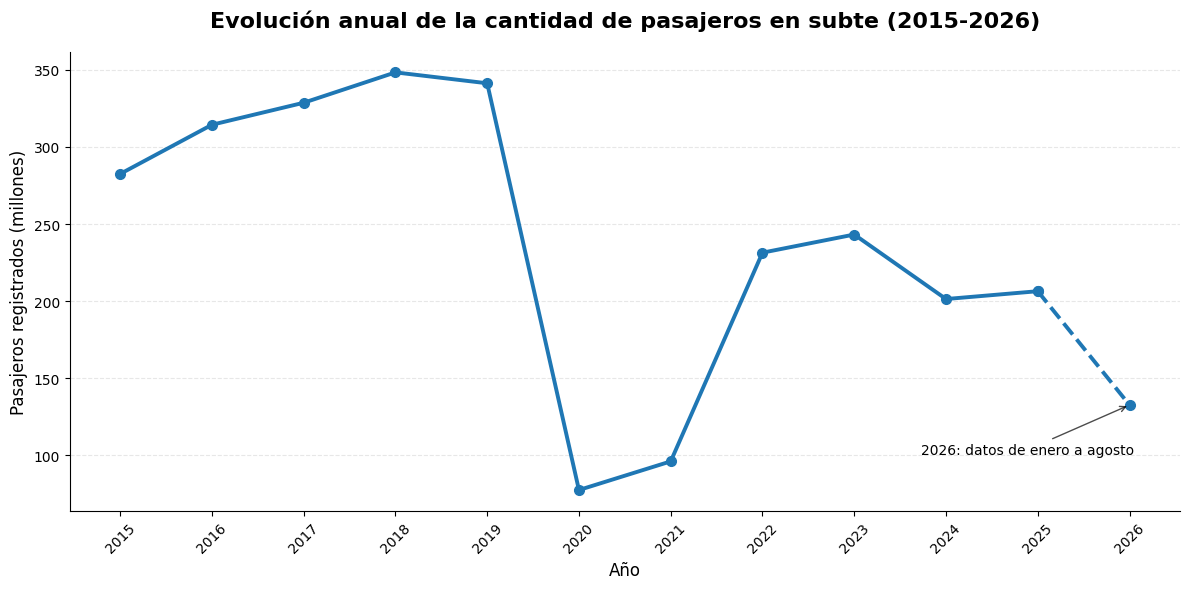

In [ ]:
# Sumamos los pasajeros registrados en cada año (sin Premetro)
lineas = ["LineaA", "LineaB", "LineaC", "LineaD", "LineaE", "LineaH"]
df_sub = df[df["linea"].isin(lineas)]

anual = df_sub.groupby("anio")["total"].sum() / 1_000_000
                                                                #tarea asistida por IA se le pidio la realizacion de un grafico de lineas sobre la evolucion anual de la cantidad de pasajeros en subte, remarcando el año 2026 con lineas puntiagudas y una aclaracion sobre que es de enero hasta agosto
# Creamos el gráfico
plt.figure(figsize=(12, 6))

# Años completos (línea continua)
plt.plot(
    anual.index[:-1],
    anual.values[:-1],
    marker="o",
    linewidth=2.8,
    markersize=7,
    color="#1f77b4"
)

# Último tramo, con 2026 parcial (línea punteada)
plt.plot(
    anual.index[-2:],
    anual.values[-2:],
    marker="o",
    linewidth=2.8,
    markersize=7,
    color="#1f77b4",
    linestyle="--"
)

# Título y nombres de los ejes
plt.title(
    "Evolución anual de la cantidad de pasajeros en subte (2015-2026)",
    fontsize=16,
    fontweight="bold",
    pad=18
)

plt.xlabel("Año", fontsize=12)
plt.ylabel("Pasajeros registrados (millones)", fontsize=12)

# Mostramos todos los años en el eje horizontal
plt.xticks(anual.index, rotation=45)

# Agregamos una cuadrícula suave
plt.grid(axis="y", linestyle="--", alpha=0.3)

# Quitamos los bordes superior y derecho
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Aclaración sobre 2026
plt.annotate(
    "2026: datos de enero a agosto",
    xy=(2026, anual.loc[2026]),
    xytext=(-150, -35),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", alpha=0.7),
    fontsize=10
)

plt.tight_layout()

# Guardamos la imagen
plt.savefig("figuras_evolucion_anual.png", dpi=300, bbox_inches="tight")

plt.show()



####*Tablas para la interpretacion*

A continuación hacemos una tabla de apoyo (asistida por IA) que imprime las cifras de la cantidad de pasajeros por año redondeados a un decimal, el porcentaje que representa cada año respecto del 2019 y otros datos para realizar una interpretación del gráfico mas detallada y precisa. También vamos a hacer estas tablas para los demás graficos de acuerdo a su contexto.

In [ ]:
import pandas as pd

# Tabla de apoyo: valores citados en la interpretación
print("Pasajeros por año (millones):")
print(anual.round(1))

print("\nPorcentaje del nivel de 2019:")
print((anual / anual[2019] * 100).round(1))  #¿que porcentaje del 2019 representa cada año?

print(f"\nCaída de 2020 respecto de 2019: {(anual[2020] / anual[2019] - 1) * 100:.1f} %") #variacion porcentual de 2020 respecto de 2019
print(f"2023 como % de 2019: {anual[2023] / anual[2019] * 100:.1f} %")
print(f"Variación 2024 vs. 2023: {(anual[2024] / anual[2023] - 1) * 100:.1f} %")
print(f"2024 por debajo de 2019: {(1 - anual[2024] / anual[2019]) * 100:.1f} %")
print(f"2025 por debajo de 2019: {(1 - anual[2025] / anual[2019]) * 100:.1f} %")

Pasajeros por año (millones):
anio
2015    282.5
2016    314.4
2017    328.7
2018    348.4
2019    341.3
2020     77.5
2021     96.1
2022    231.5
2023    243.2
2024    201.4
2025    206.5
2026    132.7
Name: total, dtype: float64

Porcentaje del nivel de 2019:
anio
2015     82.8
2016     92.1
2017     96.3
2018    102.1
2019    100.0
2020     22.7
2021     28.1
2022     67.8
2023     71.3
2024     59.0
2025     60.5
2026     38.9
Name: total, dtype: float64

Caída de 2020 respecto de 2019: -77.3 %
2023 como % de 2019: 71.3 %
Variación 2024 vs. 2023: -17.2 %
2024 por debajo de 2019: 41.0 %
2025 por debajo de 2019: 39.5 %


###***Interpretación***

La serie muestra tres etapas bien diferenciadas. Entre 2015 y 2018, la cantidad de pasajeros registrados creció de forma sostenida, de 282,5 a 348,4 millones, y en 2019 se mantuvo en un nivel similar (341,3 millones). En 2020 se observa la caída más pronunciada de toda la serie, a 77,5 millones de pasajeros (un 77 % menos que en 2019), que coincide con las restricciones a la circulación por la pandemia de COVID-19. En 2021 la recuperación es leve (96,1 millones) y en 2022 hay un salto fuerte hasta 231,5 millones, que continúa en 2023 (243,2 millones).

Sin embargo, la demanda no volvió al nivel previo a la pandemia. Incluso en su mejor año posterior (2023), el subte registró el 71 % de los pasajeros de 2019. Además, en 2024 se produce una nueva baja (a 201,4 millones, un 17 % menos que en 2023) y en 2025 el valor se mantiene en un nivel similar (206,5 millones): en ambos años, la demanda quedó entre un 39 % y un 41 % por debajo de 2019. El valor de 2026 (132,7 millones) es menor porque solo incluye datos de enero a agosto, por lo que no es comparable con los años completos y no indica por sí solo una nueva caída. Por eso se dibuja con línea punteada.

En conjunto, el gráfico indica que el subte **no recuperó** la demanda previa a la pandemia: la recuperación fue parcial y se estancó en torno al 60 % del nivel de 2019.

**Posibles explicaciones.** Los datos muestran qué ocurrió, pero no por qué. Distintos informes (por ejemplo, del Observatorio de Tarifas y Subsidios del IIEP, UBA-CONICET) atribuyen la baja demanda al avance del teletrabajo y a los aumentos de tarifa del subte desde mayo de 2024, que ampliaron la diferencia de precio con el colectivo. Estas explicaciones deben tomarse como hipótesis: con este dataset no es posible medir cuánto aporta cada factor.

**Limitaciones a tener en cuenta:**
- Se excluyó la línea Premetro (PM), que aparece en los datos recién desde junio de 2025, para que los años sean comparables.
- Las variables cuentan ingresos por los molinetes, no personas distintas.
- Desde diciembre de 2024 los archivos incluyen otros modos de pago (tarjetas y celular), por lo que podría haber un cambio en lo que se cuenta; la comparación de 2025 y 2026 con años anteriores debe interpretarse con cautela.
- Las fechas de 2020 y 2021 fueron corregidas por inferencia en la limpieza de los datos, por lo que el detalle mensual de esos años es menos confiable.

##**4.2 Comparación de la cantidad de pasajeros por línea**

En esta sección agrupamos los registros por línea de subte y sumamos la variable total para calcular la cantidad de pasajeros registrada en cada una durante el período 2015–2026. Luego, representamos los resultados mediante un gráfico de barras para comparar la demanda entre las distintas líneas e identificar cuáles concentran más viajes.

Como el análisis incluye varios años, los resultados representan el acumulado de todo el período y no la demanda actual de cada línea.

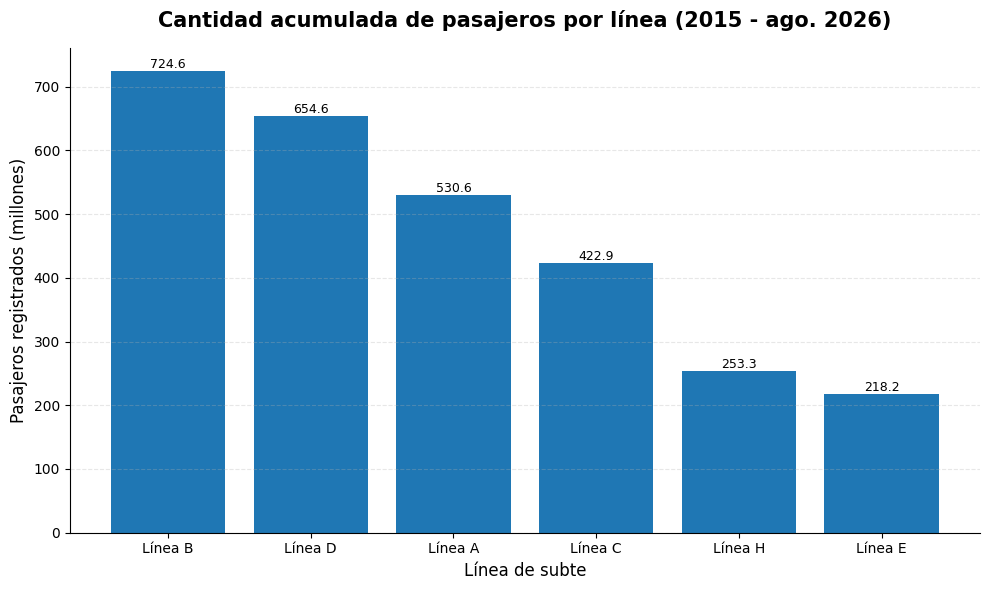

In [ ]:
#sumamos los pasajeros registrados en cada linea
lineas = ["LineaA", "LineaB", "LineaC", "LineaD", "LineaE", "LineaH"]

por_linea = (
    df[df["linea"].isin(lineas)]
    .groupby("linea")["total"].sum() / 1_000_000               #tarea asitida por IA, se le pidio la realizacion de un grafico de barras sobre la cantida de pasajeros de cada linea en (2015-2026)
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
barras = plt.bar(por_linea.index.str.replace("Linea", "Línea "), por_linea.values)

# Valores sobre las barras
for barra, valor in zip(barras, por_linea.values):
    plt.text(barra.get_x() + barra.get_width() / 2, valor,
             f"{valor:,.1f}", ha="center", va="bottom", fontsize=9)

plt.title("Cantidad acumulada de pasajeros por línea (2015 - ago. 2026)",
          fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Línea de subte", fontsize=12)
plt.ylabel("Pasajeros registrados (millones)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.3)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("figuras_pasajeros_por_linea.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Tabla de apoyo: valores citados en la interpretación
total = por_linea.sum()

tabla_lineas = pd.DataFrame({
    "Pasajeros (millones)": por_linea.round(1),
    "% del total": (por_linea / total * 100).round(1)
})
print(tabla_lineas)
print(f"\nTotal acumulado: {total:,.0f} millones")

print(f"B + D: {por_linea[['LineaB', 'LineaD']].sum() / total * 100:.1f} % del total")
print(f"H + E: {por_linea[['LineaH', 'LineaE']].sum() / total * 100:.1f} % del total")

        Pasajeros (millones)  % del total
linea                                    
LineaB                 724.6         25.8
LineaD                 654.6         23.3
LineaA                 530.6         18.9
LineaC                 422.9         15.1
LineaH                 253.3          9.0
LineaE                 218.2          7.8

Total acumulado: 2,804 millones
B + D: 49.2 % del total
H + E: 16.8 % del total



### ***Interpretación***

El gráfico muestra cuántos ingresos por los molinetes acumuló cada línea entre 2015 y agosto de 2026. La distribución es muy desigual: la línea B (724,6 millones, 25,8 % del total) y la línea D (654,6 millones, 23,3 %) concentran, entre las dos, cerca de la mitad de todos los ingresos registrados (49,2 % de un total de 2.804 millones). Les siguen la línea A (530,6 millones, 18,9 %) y la línea C (422,9 millones, 15,1 %). Las líneas H y E son las de menor volumen (253,3 y 218,2 millones; 9,0 % y 7,8 %), y juntas representan el 16,8 % del total.

En el contexto del dataset, esto significa que la demanda del subte está muy concentrada en pocas líneas: dos de las seis líneas explican casi la mitad de los ingresos. Este resultado responde a la parte de la pregunta del trabajo sobre *dónde* se viaja, pero solo en términos de volumen: no dice cómo cambió la demanda de cada línea con el tiempo, y eso se analiza más adelante comparando cada línea con su nivel de 2019. Tampoco indica que una línea funcione mejor que otra, porque las líneas difieren en longitud, cantidad de estaciones y zonas que conectan, y la línea E, por ejemplo, incorporó tres estaciones en junio de 2019.

**Cómo leer este gráfico:**
- Los valores son **acumulados** de todo el período, que incluye los años de pandemia y 2026 solo hasta agosto. Sirven para ver qué líneas concentran más ingresos, no para comparar su evolución.
- Las diferencias entre líneas reflejan en parte su tamaño (largo de la línea y cantidad de estaciones), no solo cuánto se la usa.
- Se excluyó el Premetro (PM), que aparece en los datos recién desde junio de 2025 y no es comparable con las líneas A, B, C, D, E y H.
- Las variables cuentan ingresos por los molinetes, no personas distintas.

##**4.3 Distribución de los viajes según la hora del día**

En esta sección analizamos la relación entre la hora del día y la cantidad de pasajeros registrados. Para ello, calculamos la cantidad promedio de pasajeros por hora y representamos los resultados mediante un gráfico de dispersión. Esta visualización permite observar cómo varía la demanda según el horario e identificar posibles patrones de uso del subte.

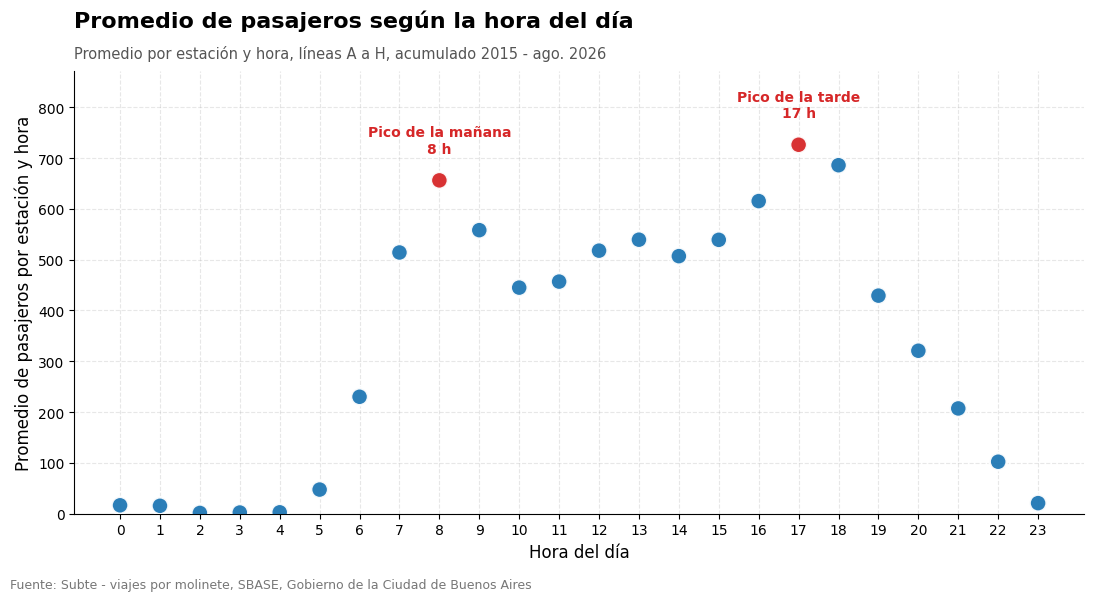

In [ ]:
import matplotlib.pyplot as plt

# Solo líneas A a H (sin Premetro)
lineas = ["LineaA", "LineaB", "LineaC", "LineaD", "LineaE", "LineaH"]
df_sub = df[df["linea"].isin(lineas)]

# Promedio de pasajeros por estación y hora, para cada hora del día
pasajeros_hora = df_sub.groupby("hora")["total"].mean()
horas = pasajeros_hora.index
valores = pasajeros_hora.values

# Pico de la mañana y de la tarde (se calculan solos)
pico_manana = pasajeros_hora.loc[5:12].idxmax()
pico_tarde = pasajeros_hora.loc[13:23].idxmax()

azul = "#1f77b4"
rojo = "#d62728"
colores = [rojo if h in (pico_manana, pico_tarde) else azul for h in horas]

fig, ax = plt.subplots(figsize=(11, 6))

# Gráfico de dispersión
ax.scatter(
    horas, valores,
    s=150, c=colores,
    edgecolors="white", linewidths=1.8,
    alpha=0.95, zorder=3
)

# Anotación de los picos
for h, nombre in [(pico_manana, "Pico de la mañana"), (pico_tarde, "Pico de la tarde")]:
    ax.annotate(
        f"{nombre}\n{h} h",
        xy=(h, pasajeros_hora.loc[h]),
        xytext=(0, 20),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=rojo
    )

# Título, subtítulo y ejes
ax.set_title(
    "Promedio de pasajeros según la hora del día",
    fontsize=16, fontweight="bold", loc="left", pad=32
)
ax.text(
    0, 1.03,
    "Promedio por estación y hora, líneas A a H, acumulado 2015 - ago. 2026",
    transform=ax.transAxes, fontsize=10.5, color="#555555"
)

ax.set_xlabel("Hora del día", fontsize=12)
ax.set_ylabel("Promedio de pasajeros por estación y hora", fontsize=12)

ax.set_xticks(range(0, 24))
ax.set_ylim(0, valores.max() * 1.2)
ax.grid(linestyle="--", alpha=0.3, zorder=0)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Fuente al pie
fig.text(
    0.01, 0.01,
    "Fuente: Subte - viajes por molinete, SBASE, Gobierno de la Ciudad de Buenos Aires",
    fontsize=9, color="#777777"
)

plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig("figuras_hora_pasajeros.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Tabla de apoyo: valores citados en la interpretación
print("Promedio de pasajeros por estación y hora:")
print(pasajeros_hora.round(1))

print(f"\nPico de la mañana: {pico_manana} h ({pasajeros_hora[pico_manana]:.0f} pasajeros)")
print(f"Pico de la tarde: {pico_tarde} h ({pasajeros_hora[pico_tarde]:.0f} pasajeros)")

mediodia = pasajeros_hora.loc[12:15]
pico = pasajeros_hora[pico_tarde]
print(f"\nDe 12 a 15 h: entre {mediodia.min():.0f} y {mediodia.max():.0f} pasajeros")
print(f"Como % del pico de la tarde: entre {mediodia.min() / pico * 100:.0f} % y {mediodia.max() / pico * 100:.0f} %")

Promedio de pasajeros por estación y hora:
hora
0      16.6
1      15.6
2       1.5
3       2.4
4       2.8
5      47.5
6     230.2
7     514.1
8     656.1
9     558.1
10    445.0
11    456.9
12    517.8
13    539.3
14    506.9
15    539.1
16    615.3
17    726.2
18    685.9
19    429.2
20    320.8
21    207.2
22    102.3
23     20.8
Name: total, dtype: float64

Pico de la mañana: 8 h (656 pasajeros)
Pico de la tarde: 17 h (726 pasajeros)

De 12 a 15 h: entre 507 y 539 pasajeros
Como % del pico de la tarde: entre 70 % y 74 %


### ***Interpretación***

El gráfico muestra un patrón de dos picos bien marcados: uno a las 8 h (655 pasajeros en promedio por estación y hora) y otro, más alto, a las 17 h (726). Entre ambos, la demanda baja pero se mantiene en un nivel alto durante el mediodía y las primeras horas de la tarde: de las 12 a las 15 h el promedio ronda entre 517 y 539 pasajeros,  cerca del 70-74 % del pico de la tarde. Entre las 2 y las 4 h los valores son prácticamente nulos y desde las 18 h descienden de forma sostenida hasta la noche.

En el contexto del dataset, esto es el patrón típico de un sistema de transporte usado sobre todo para ir y volver del trabajo y del estudio. El pico de la mañana corresponde a los ingresos de quienes viajan hacia sus destinos y el de la tarde a quienes regresan. Que el segundo sea más alto podría deberse a que la vuelta se reparte en más horarios y motivos (compras, trámites, actividades de la tarde), aunque con estos datos no se puede comprobar. Los valores casi nulos de la madrugada son esperables porque el servicio no funciona en esas horas. Al mismo tiempo, que el mediodía no sea un valle profundo indica que el subte tiene una demanda importante durante todo el día y no solo en las horas pico. Para la pregunta del trabajo, esto significa que la demanda depende mucho de los horarios laborales, por lo que cambios como el teletrabajo podrían afectar sobre todo a las horas pico.

**Cómo leer este gráfico:**
- Los valores son **promedios de todo el período** (2015 a agosto de 2026), que incluye la pandemia, fines de semana y feriados. Mezclar días hábiles con fines de semana suaviza los picos, así que el patrón real de lunes a viernes es probablemente más marcado.
- Al promediar todos los años no permite ver si el patrón **cambió** después de la pandemia. Para eso habría que comparar, por ejemplo, 2019 con 2024-2025.
- Cada estación se cuenta una vez por línea, por lo que las estaciones de combinación aparecen en cada una de sus líneas.
- Se excluyó el Premetro (PM) porque aparece en los datos recién desde junio de 2025 y no es comparable con las líneas A, B, C, D, E y H.
- Las variables cuentan ingresos por los molinetes, no personas distintas.

## **4.4 Cambios en la hora en que se viaja: 2019 vs. 2024-2025**

**Qué se busca y qué se hizo:** Este gráfico busca responder si cambió *cuándo* se viaja en subte después de la pandemia. Para eso se compara 2019 (último año completo previo a la pandemia) con 2024-2025 (los años completos más recientes) usando las líneas A, B, C, D, E y H. Como el total de pasajeros cayó entre ambas épocas, no se comparan cantidades sino el **porcentaje de los pasajeros de cada período que viaja en cada hora**, lo que permite ver si cambió la forma del día y no solo su nivel. Se representa con un gráfico de dispersión, con un color por período.

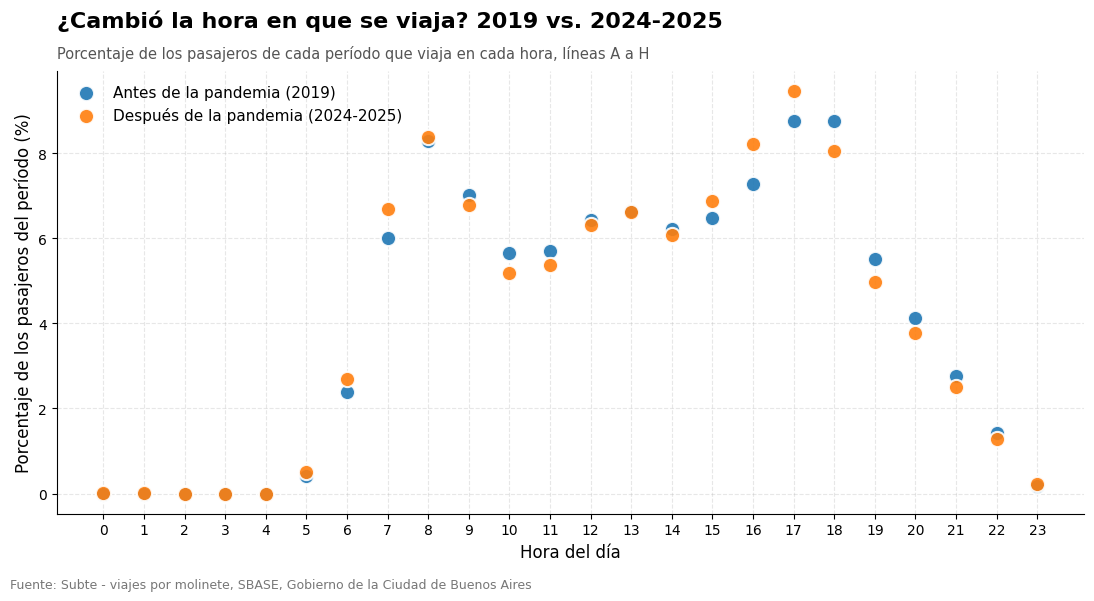

In [ ]:


# Solo líneas A a H (sin Premetro)
lineas = ["LineaA", "LineaB", "LineaC", "LineaD", "LineaE", "LineaH"]
df_sub = df[df["linea"].isin(lineas)]

# Períodos a comparar
antes = df_sub[df_sub["anio"] == 2019]
despues = df_sub[df_sub["anio"].isin([2024, 2025])]

# Porcentaje de los pasajeros del período que viaja en cada hora
def perfil_horario(d):
    return d.groupby("hora")["total"].sum() / d["total"].sum() * 100

p_antes = perfil_horario(antes)
p_despues = perfil_horario(despues)

azul = "#1f77b4"
naranja = "#ff7f0e"

fig, ax = plt.subplots(figsize=(11, 6))

ax.scatter(p_antes.index, p_antes.values, s=120, color=azul,
           edgecolors="white", linewidths=1.5, alpha=0.9,
           label="Antes de la pandemia (2019)", zorder=3)
ax.scatter(p_despues.index, p_despues.values, s=120, color=naranja,
           edgecolors="white", linewidths=1.5, alpha=0.9,
           label="Después de la pandemia (2024-2025)", zorder=3)

ax.set_title("¿Cambió la hora en que se viaja? 2019 vs. 2024-2025",
             fontsize=16, fontweight="bold", loc="left", pad=32)
ax.text(0, 1.03,
        "Porcentaje de los pasajeros de cada período que viaja en cada hora, líneas A a H",
        transform=ax.transAxes, fontsize=10.5, color="#555555")

ax.set_xlabel("Hora del día", fontsize=12)
ax.set_ylabel("Porcentaje de los pasajeros del período (%)", fontsize=12)

ax.set_xticks(range(0, 24))
ax.grid(linestyle="--", alpha=0.3, zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, fontsize=11)

fig.text(0.01, 0.01,
         "Fuente: Subte - viajes por molinete, SBASE, Gobierno de la Ciudad de Buenos Aires",
         fontsize=9, color="#777777")

plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig("figuras_hora_antes_despues.png", dpi=300, bbox_inches="tight")
plt.show()



In [ ]:
# Tabla de apoyo: valores citados en la interpretación
dif = p_despues - p_antes

tabla_horas = pd.DataFrame({
    "2019 (%)": p_antes.round(1),
    "2024-2025 (%)": p_despues.round(1),
    "Diferencia (p. p.)": dif.round(2)
})
print(tabla_horas)

# Control: cada período reparte el 100 % entre las 24 horas
print(f"\nSuma de cada período: {p_antes.sum():.1f} % y {p_despues.sum():.1f} %")
print(f"Mayor cambio absoluto: {dif.abs().max():.2f} p. p. (hora {dif.abs().idxmax()})")

# Suma de diferencias por tramo horario
tramos = {"6 y 7 h": (6, 7), "9 a 12 h": (9, 12),
          "15 a 17 h": (15, 17), "18 a 22 h": (18, 22)}
print("\nDiferencia acumulada por tramo (p. p.):")
for nombre, (a, b) in tramos.items():
    print(f"{nombre}: {dif.loc[a:b].sum():+.2f}")

      2019 (%)  2024-2025 (%)  Diferencia (p. p.)
hora                                             
0          0.0            0.0                0.02
1          0.0            0.0                0.00
2          0.0            0.0               -0.00
3          0.0            0.0                0.00
4          0.0            0.0               -0.00
5          0.4            0.5                0.10
6          2.4            2.7                0.31
7          6.0            6.7                0.68
8          8.3            8.4                0.08
9          7.0            6.8               -0.24
10         5.6            5.2               -0.46
11         5.7            5.4               -0.31
12         6.4            6.3               -0.13
13         6.6            6.6               -0.03
14         6.2            6.1               -0.14
15         6.5            6.9                0.40
16         7.3            8.2                0.95
17         8.8            9.5                0.69


### ***Interpretación***

Las dos curvas son muy parecidas: en ambos períodos hay un pico a las 8 h, una meseta al mediodía y un segundo pico, el más alto, a las 17 h. Esto indica que la **distribución horaria de la demanda cambió poco** entre 2019 y 2024-2025: ninguna hora varió su participación en más de 1 punto porcentual.

Dentro de esa estabilidad hay un corrimiento pequeño pero consistente. Ganaron peso las primeras horas de la mañana (las 6 y 7 h, +0,3 y +0,7 puntos) y el tramo de 15 a 17 h (+0,4, +1,0 y +0,7 puntos). Perdieron peso el mediodía (de 9 a 12 h, hasta -0,5 puntos) y, sobre todo, el tramo de 18 a 22 h (entre -0,1 y -0,7 puntos). Como el total de pasajeros cayó entre ambas épocas, esto significa que las horas pico de entrada y de regreso retuvieron mejor su demanda que el resto del día. Una explicación posible es que los viajes por trabajo o estudio se mantuvieron más que los viajes de mediodía y de la noche, y que el regreso se concentra un poco más temprano, pero con estos datos no se puede comprobar.

En el contexto de la pregunta del trabajo, el resultado es que el subte **no recuperó el nivel de pasajeros previo a la pandemia, pero el patrón horario de uso se mantuvo casi igual**: se viaja principalmente en las mismas horas, aunque con menos pasajeros en total y con un poco más de peso de las horas pico de la tarde.

**Cómo leer este gráfico:**
- Muestra **proporciones**, no cantidades: que una hora tenga un porcentaje parecido no significa que tenga la misma cantidad de pasajeros, ya que el total de 2024-2025 es menor. Una hora que "gana peso" puede haber perdido pasajeros, pero menos que el resto.
- No separa días hábiles de fines de semana, por lo que los picos aparecen suavizados.
- Desde diciembre de 2024 el dataset podría incluir otros medios de pago, por lo que 2025 es el año con mayor incertidumbre.
- Se excluyó el Premetro (PM), que aparece en los datos recién desde junio de 2025.
- Las variables cuentan ingresos por los molinetes, no personas distintas.

## **4.5 Cambios en el día en que se viaja: 2019 vs. 2024-2025**





**Qué se busca y qué se hizo:** Este gráfico busca responder si cambió *qué días de la semana* se viaja en subte después de la pandemia. Para eso se compara 2019 (último año completo previo a la pandemia) con 2024-2025 (los años completos más recientes) usando las líneas A, B, C, D, E y H. Se agruparon dos años en el período posterior para tener más datos y suavizar posibles años atípicos. Primero se sumaron los pasajeros de cada día calendario y luego se calculó el promedio de cada día de la semana; después ese promedio se expresó como porcentaje de los pasajeros de toda la semana. Así se compara la **forma de la semana** y no su nivel, que cayó entre ambas épocas, y el resultado no depende de que un período incluya uno o dos años. Se representa con barras agrupadas, con un color por período.

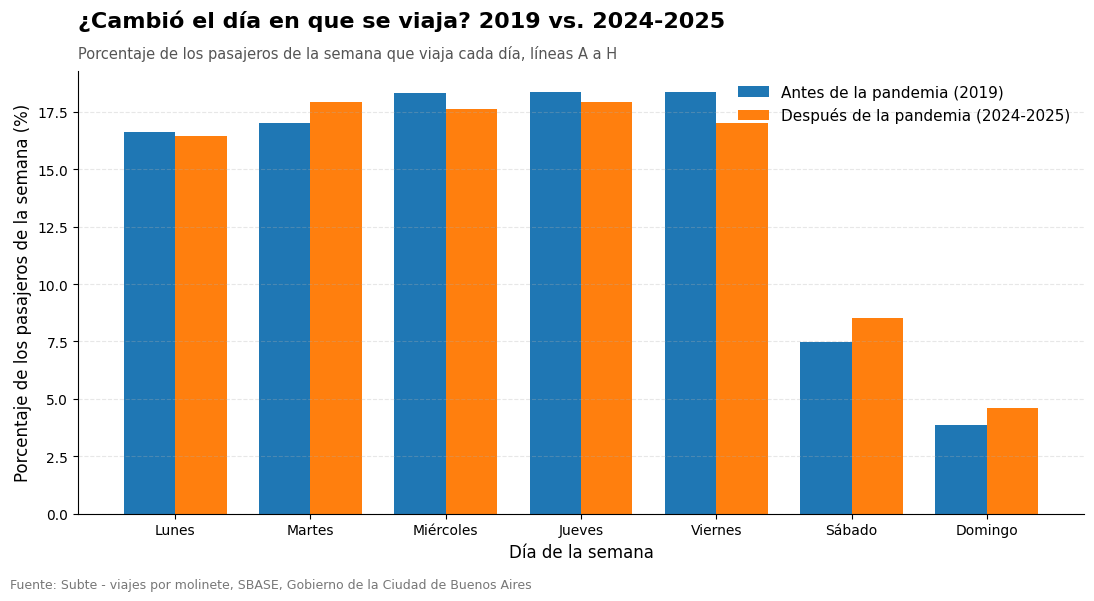

Promedio de pasajeros por día (millones):
            2019  2024-2025
Lunes      1.100      0.644
Martes     1.125      0.702
Miércoles  1.211      0.689
Jueves     1.214      0.702
Viernes    1.213      0.666
Sábado     0.494      0.334
Domingo    0.255      0.180

Diferencia en puntos porcentuales (2024-2025 menos 2019):
Lunes       -0.19
Martes       0.91
Miércoles   -0.71
Jueves      -0.44
Viernes     -1.35
Sábado       1.05
Domingo      0.73
Name: total, dtype: float64
Variación del promedio de pasajeros por día (%):
Lunes       -41.4
Martes      -37.6
Miércoles   -43.1
Jueves      -42.2
Viernes     -45.1
Sábado      -32.4
Domingo     -29.5
Name: total, dtype: float64

Promedio semanal total: 6.61 → 3.92 millones (-40.8 %)
Suma de cada período: 100.0 % y 100.0 %


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Solo líneas A a H (sin Premetro)
lineas = ["LineaA", "LineaB", "LineaC", "LineaD", "LineaE", "LineaH"]
df_sub = df[df["linea"].isin(lineas)]

antes = df_sub[df_sub["anio"] == 2019].copy()
despues = df_sub[df_sub["anio"].isin([2024, 2025])].copy()

dias = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]

def perfil_semanal(d):
    d["fecha"] = pd.to_datetime(d["fecha"])
    # Total de pasajeros de cada día calendario
    por_fecha = d.groupby("fecha")["total"].sum()
    # Promedio por día de la semana
    promedio = por_fecha.groupby(por_fecha.index.dayofweek).mean()
    promedio.index = dias
    # Porcentaje de los pasajeros de la semana que viaja cada día
    porcentaje = promedio / promedio.sum() * 100
    return promedio, porcentaje

prom_antes, pct_antes = perfil_semanal(antes)
prom_despues, pct_despues = perfil_semanal(despues)

# Gráfico de barras agrupadas
azul = "#1f77b4"
naranja = "#ff7f0e"
x = np.arange(len(dias))
ancho = 0.38

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(x - ancho / 2, pct_antes.values, ancho, color=azul,
       label="Antes de la pandemia (2019)")
ax.bar(x + ancho / 2, pct_despues.values, ancho, color=naranja,
       label="Después de la pandemia (2024-2025)")

ax.set_title("¿Cambió el día en que se viaja? 2019 vs. 2024-2025",
             fontsize=16, fontweight="bold", loc="left", pad=32)
ax.text(0, 1.03,
        "Porcentaje de los pasajeros de la semana que viaja cada día, líneas A a H",
        transform=ax.transAxes, fontsize=10.5, color="#555555")

ax.set_xlabel("Día de la semana", fontsize=12)
ax.set_ylabel("Porcentaje de los pasajeros de la semana (%)", fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(dias)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, fontsize=11)

fig.text(0.01, 0.01,
         "Fuente: Subte - viajes por molinete, SBASE, Gobierno de la Ciudad de Buenos Aires",
         fontsize=9, color="#777777")

plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig("figuras_dia_antes_despues.png", dpi=300, bbox_inches="tight")
plt.show()

# Tablas para la interpretación
print("Promedio de pasajeros por día (millones):")
print((pd.DataFrame({"2019": prom_antes, "2024-2025": prom_despues}) / 1e6).round(3))
print("\nDiferencia en puntos porcentuales (2024-2025 menos 2019):")
print((pct_despues - pct_antes).round(2))
# Variación en cantidad de pasajeros, 2024-2025 vs. 2019
variacion = ((prom_despues / prom_antes - 1) * 100).round(1)
print("Variación del promedio de pasajeros por día (%):")
print(variacion)

sem_antes, sem_despues = prom_antes.sum(), prom_despues.sum()
print(f"\nPromedio semanal total: {sem_antes / 1e6:.2f} → {sem_despues / 1e6:.2f} millones "
      f"({(sem_despues / sem_antes - 1) * 100:.1f} %)")

# Control: cada período reparte el 100 % entre los 7 días
print(f"Suma de cada período: {pct_antes.sum():.1f} % y {pct_despues.sum():.1f} %")

In [ ]:
# Tabla de apoyo: Porcentaje de los pasajeros de la semana por día y días hábiles vs. fin de semana
habiles = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes"]
finde = ["Sábado", "Domingo"]

tabla_dias = pd.DataFrame({
    "2019 (%)": pct_antes,
    "2024-2025 (%)": pct_despues,
    "Diferencia (p. p.)": pct_despues - pct_antes
}).round(1)
print("Porcentaje de los pasajeros de la semana que viaja cada día:")
print(tabla_dias)

resumen = pd.DataFrame({
    "2019 (%)": [pct_antes[habiles].sum(), pct_antes[finde].sum()],
    "2024-2025 (%)": [pct_despues[habiles].sum(), pct_despues[finde].sum()]
}, index=["Lunes a viernes", "Sábado y domingo"])
resumen["Diferencia (p. p.)"] = resumen["2024-2025 (%)"] - resumen["2019 (%)"]
print("\nDías hábiles vs. fin de semana:")
print(resumen.round(1))

Porcentaje de los pasajeros de la semana que viaja cada día:
           2019 (%)  2024-2025 (%)  Diferencia (p. p.)
Lunes          16.6           16.4                -0.2
Martes         17.0           17.9                 0.9
Miércoles      18.3           17.6                -0.7
Jueves         18.4           17.9                -0.4
Viernes        18.4           17.0                -1.4
Sábado          7.5            8.5                 1.1
Domingo         3.9            4.6                 0.7

Días hábiles vs. fin de semana:
                  2019 (%)  2024-2025 (%)  Diferencia (p. p.)
Lunes a viernes       88.7           86.9                -1.8
Sábado y domingo      11.3           13.1                 1.8


### ***Interpretación***

En ambos períodos, la demanda se concentra de lunes a viernes, con entre 16 % y 18 % de los pasajeros de la semana por día, mientras que el sábado ronda el 8 % y el domingo entre el 4 % y el 5 %. Esto indica que la **estructura básica de la semana se mantuvo**: el subte se sigue usando sobre todo en días laborales.

Dentro de esa estabilidad hay un corrimiento. De lunes a viernes el peso conjunto pasó del 88,7 % al 86,9 %, y el fin de semana subió del 11,3 % al 13,1 % (1,8 puntos porcentuales). El viernes es el día que más peso perdió (1,4 puntos), seguido por el miércoles (0,7) y el jueves (0,4), mientras que el sábado y el domingo ganaron 1,1 y 0,7 puntos. El martes ganó 0,9 puntos y el lunes casi no cambió (-0,2).

Estos cambios de proporción se explican por cómo cayó cada día en cantidad de pasajeros. Entre 2019 y 2024-2025, **todos los días perdieron pasajeros**: de lunes a viernes las caídas fueron de entre 37,6 % (martes) y 45,1 % (viernes), mientras que el sábado cayó 32,4 % y el domingo 29,5 %. Los fines de semana ganan peso porque cayeron menos, no porque hayan crecido. Una explicación posible es que parte de los viajes laborales dejaron de realizarse, por ejemplo por el trabajo remoto o híbrido, mientras que los viajes de ocio y trámites de fin de semana se mantuvieron mejor, pero con estos datos no se puede comprobar. Que el viernes sea el día con mayor caída es compatible con esa idea, aunque no la demuestra.

En el contexto de la pregunta del trabajo, el resultado es que **la caída de la demanda afectó a toda la semana, con mayor intensidad en los días hábiles que en los fines de semana**. Junto con el análisis por hora, el patrón de uso cambió poco en su forma, aunque con menos pasajeros en total.

**Cómo leer este gráfico:**
- Las barras muestran **proporciones**, no cantidades: un día que gana peso no necesariamente tiene más pasajeros. Las cantidades están en la tabla de apoyo.
- Se agrupa por día de la semana, por lo que los feriados cuentan como el día que corresponda (un lunes feriado se promedia con los demás lunes).
- En 2019 faltan algunos días en los datos (por ejemplo, en abril y mayo).
- Desde diciembre de 2024 el dataset podría incluir otros medios de pago, por lo que 2025 es el año con mayor incertidumbre.
- Se excluyó el Premetro (PM), que aparece en los datos recién desde junio de 2025.
- Las variables cuentan ingresos por los molinetes, no personas distintas.

## **4.6 Recuperación de cada línea respecto de 2019**

**Qué se busca y qué se hizo:** Este gráfico busca responder *dónde* cambió la demanda del subte, en particular si todas las líneas se recuperaron de la pandemia por igual. Para eso se calculó, para las líneas A, B, C, D, E y H (se excluyó el Premetro), cuántos pasajeros registró cada una en 2019 (último año completo previo a la pandemia) y cuántos registró en promedio por año en 2024-2025 (los dos últimos años completos, por eso el total de ambos años se divide por 2 para comparar un año contra un año). Luego se expresó el segundo valor como porcentaje del primero: 100 % significa que la línea volvió al nivel de 2019. Se representa con un gráfico de barras, con una línea de referencia en 100 % y otra con el promedio del sistema completo.

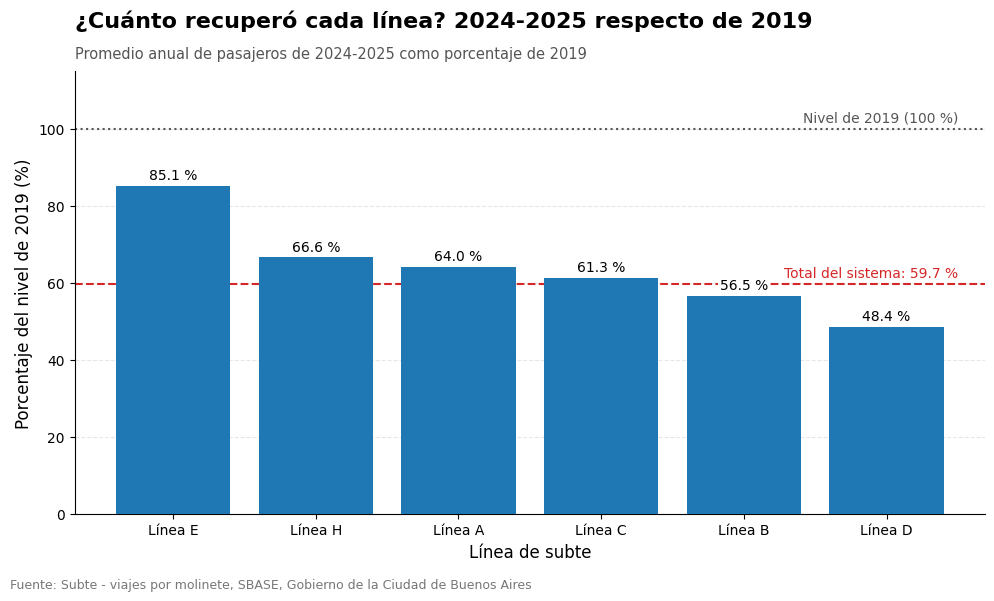

        2019 (millones)  Promedio anual 2024-2025 (millones)  \
linea                                                          
LineaE             24.1                                 20.5   
LineaH             34.7                                 23.1   
LineaA             63.5                                 40.6   
LineaC             50.7                                 31.0   
LineaB             87.4                                 49.4   
LineaD             80.9                                 39.2   

        % del nivel de 2019  
linea                        
LineaE                 85.1  
LineaH                 66.6  
LineaA                 64.0  
LineaC                 61.3  
LineaB                 56.5  
LineaD                 48.4  

Total del sistema: 341.3 → 203.9 millones (59.7 % del nivel de 2019)
        Pasajeros perdidos (millones)  % de la pérdida total  \
linea                                                          
LineaE                            3.6            

In [ ]:

# Solo líneas A a H (sin Premetro)
lineas = ["LineaA", "LineaB", "LineaC", "LineaD", "LineaE", "LineaH"]
df_sub = df[df["linea"].isin(lineas)]

antes = df_sub[df_sub["anio"] == 2019]
despues = df_sub[df_sub["anio"].isin([2024, 2025])]

# Pasajeros por línea (millones): 2019 y promedio anual de 2024-2025
pasajeros_antes = antes.groupby("linea")["total"].sum() / 1_000_000
pasajeros_despues = despues.groupby("linea")["total"].sum() / 2 / 1_000_000

# Porcentaje del nivel de 2019 que alcanzó cada línea
recuperacion = (pasajeros_despues / pasajeros_antes * 100).sort_values(ascending=False)
recuperacion_total = pasajeros_despues.sum() / pasajeros_antes.sum() * 100

azul = "#1f77b4"

fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.bar(recuperacion.index.str.replace("Linea", "Línea "),
                recuperacion.values, color=azul, zorder=3)

# Valores sobre las barras (con fondo blanco para que no los tape la línea roja)
for barra, valor in zip(barras, recuperacion.values):
    ax.text(barra.get_x() + barra.get_width() / 2, valor + 1,
            f"{valor:.1f} %", ha="center", va="bottom", fontsize=10,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.5), zorder=4)

# Referencias: nivel de 2019 y recuperación del sistema completo
ax.axhline(100, color="#555555", linestyle=":", linewidth=1.5, zorder=2)
ax.text(len(recuperacion) - 0.5, 101, "Nivel de 2019 (100 %)",
        ha="right", va="bottom", fontsize=10, color="#555555")

ax.axhline(recuperacion_total, color="#d62728", linestyle="--", linewidth=1.5, zorder=2)
ax.text(len(recuperacion) - 0.5, recuperacion_total + 1,
        f"Total del sistema: {recuperacion_total:.1f} %",
        ha="right", va="bottom", fontsize=10, color="#d62728")

ax.set_title("¿Cuánto recuperó cada línea? 2024-2025 respecto de 2019",
             fontsize=16, fontweight="bold", loc="left", pad=32)
ax.text(0, 1.03,
        "Promedio anual de pasajeros de 2024-2025 como porcentaje de 2019",
        transform=ax.transAxes, fontsize=10.5, color="#555555")

ax.set_xlabel("Línea de subte", fontsize=12)
ax.set_ylabel("Porcentaje del nivel de 2019 (%)", fontsize=12)
ax.set_ylim(0, 115)
ax.grid(axis="y", linestyle="--", alpha=0.3, zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(0.01, 0.01,
         "Fuente: Subte - viajes por molinete, SBASE, Gobierno de la Ciudad de Buenos Aires",
         fontsize=9, color="#777777")

plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig("figuras_recuperacion_por_linea.png", dpi=300, bbox_inches="tight")
plt.show()
# Tabla de apoyo para la interpretación
tabla_recuperacion = pd.DataFrame({
    "2019 (millones)": pasajeros_antes,
    "Promedio anual 2024-2025 (millones)": pasajeros_despues,
    "% del nivel de 2019": recuperacion
}).loc[recuperacion.index].round(1)

print(tabla_recuperacion)
print(f"\nTotal del sistema: {pasajeros_antes.sum():.1f} → {pasajeros_despues.sum():.1f} millones "
      f"({recuperacion_total:.1f} % del nivel de 2019)")
# Pasajeros perdidos por línea y peso de cada línea en el sistema
perdidos = (pasajeros_antes - pasajeros_despues).loc[recuperacion.index]
peso_antes = pasajeros_antes / pasajeros_antes.sum() * 100
peso_despues = pasajeros_despues / pasajeros_despues.sum() * 100

tabla_pesos = pd.DataFrame({
    "Pasajeros perdidos (millones)": perdidos,
    "% de la pérdida total": perdidos / perdidos.sum() * 100,
    "Peso en 2019 (%)": peso_antes,
    "Peso en 2024-2025 (%)": peso_despues
}).loc[recuperacion.index].round(1)

print(tabla_pesos)
print(f"\nB + D: {perdidos[['LineaB', 'LineaD']].sum() / perdidos.sum() * 100:.1f} % de la pérdida total, "
      f"{peso_antes[['LineaB', 'LineaD']].sum():.1f} % de los pasajeros de 2019")

In [ ]:
# Línea E sin las tres estaciones inauguradas en junio de 2019
nuevas_E = ["CORREO CENTRAL", "CATALINAS", "RETIRO"]

e_antes = antes[(antes["linea"] == "LineaE") & (~antes["estacion"].isin(nuevas_E))]["total"].sum() / 1_000_000
e_despues = despues[(despues["linea"] == "LineaE") & (~despues["estacion"].isin(nuevas_E))]["total"].sum() / 2 / 1_000_000

print(f"Línea E sin estaciones nuevas: {e_antes:.1f} → {e_despues:.1f} millones "
      f"({e_despues / e_antes * 100:.1f} % del nivel de 2019)")

# Meses de 2019 con datos de Correo Central (debería empezar en junio)
meses = sorted(antes[(antes["linea"] == "LineaE") & (antes["estacion"] == "CORREO CENTRAL")]["fecha"].dt.month.unique())
print("Meses de 2019 con datos de Correo Central:", meses)

Línea E sin estaciones nuevas: 21.3 → 16.8 millones (78.8 % del nivel de 2019)
Meses de 2019 con datos de Correo Central: [np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12)]


### ***Interpretación***

Ninguna línea recuperó el nivel de 2019, y la recuperación fue muy despareja: va de 48,4 % en la línea D a 85,1 % en la línea E. El sistema completo alcanzó el 59,7 % del nivel de 2019 (de 341,3 a 203,8 millones de pasajeros por año), lo que es coherente con el gráfico de evolución anual. Las líneas E (85,1 %), H (66,6 %), A (64,0 %) y C (61,3 %) quedaron por encima del promedio del sistema, y las líneas B (56,5 %) y D (48,4 %) por debajo. En la línea D, hoy viaja menos de la mitad de los pasajeros que en 2019.

En cantidades, la pérdida se concentra en las líneas que más gente movían: la línea D perdió 41,7 millones de pasajeros por año y la B 38,0 millones, lo que suma cerca del 58 % de toda la pérdida del sistema, siendo que estas dos líneas representaban cerca del 49 % de los pasajeros de 2019. Como consecuencia, cambió el peso de cada línea: la D pasó de concentrar el 23,7 % de los pasajeros a el 19,2 %, y pasó del segundo al tercer lugar en cantidad de pasajeros, detrás de la A (40,6 millones contra 39,2). La línea E, en cambio, subió de 7,1 % a 10,1 % del total ( en parte por la ampliación de 2019), y la H de 10,2 % a 11,3 %. La línea B se mantiene como la más usada.

En el contexto de la pregunta del trabajo, esto significa que *dónde* se viaja cambió de forma moderada: el subte sigue concentrado en las mismas líneas, pero las líneas más cargadas en 2019 (sobre todo la D y la B) perdieron más que las demás. Con estos datos no se puede explicar por qué. Con estos datos no se puede explicar por qué las líneas se recuperaron de forma distinta. La línea E es un caso particular: el 3 de junio de 2019 se inauguraron tres estaciones nuevas (Correo Central, Catalinas y Retiro), por lo que en 2019 la línea tuvo esas estaciones solo siete meses y su recuperación (85,1 %) no es comparable con la de las demás. Sin esas tres estaciones, la línea E alcanza el 78,8 % del nivel de 2019 (de 21,3 a 16,8 millones de pasajeros por año), que sigue siendo la mayor recuperación entre las líneas, aunque es posible que las estaciones originales también se hayan beneficiado de la ampliación, por las nuevas combinaciones con las líneas B y C.

**Cómo leer este gráfico:**
- Compara **cantidades de pasajeros** (no proporciones): cada barra es el promedio anual de 2024-2025 como porcentaje de 2019.
- El valor de 2024-2025 es el promedio de dos años, y 2025 tiene la incertidumbre de los otros medios de pago desde diciembre de 2024.
- En 2019 faltan algunos días en los datos (abril y mayo), por lo que los porcentajes podrían estar levemente sobreestimados (en menos de 1 punto porcentual).
-  La línea E incorporó tres estaciones (Correo Central, Catalinas y Retiro) el 3 de junio de 2019, por lo que su recuperación no es comparable con la de las demás líneas. No se verificaron cambios en la red en las otras líneas.
- Se excluyó el Premetro (PM), que aparece en los datos recién desde junio de 2025.
- Las variables cuentan ingresos por los molinetes, no personas distintas.

## **4.7 Dónde se viaja: las estaciones con más pasajeros**

**Qué se busca y qué se hizo:** Este gráfico busca responder dónde cambió la demanda del subte a nivel de estación. Para eso se tomaron las líneas A, B, C, D, E y H (se excluyó el Premetro) y se calculó cuántos pasajeros registró cada estación en 2019 (último año completo previo a la pandemia) y en promedio por año en 2024-2025 (el total de los dos años se divide por 2, para comparar un año contra un año). Se muestran las 10 estaciones con más pasajeros en 2019, con barras horizontales agrupadas y un color por período. Cada estación se cuenta dentro de su línea: las estaciones de combinación (por ejemplo, Retiro en las líneas C y E) aparecen por separado, porque los datos las registran por línea.

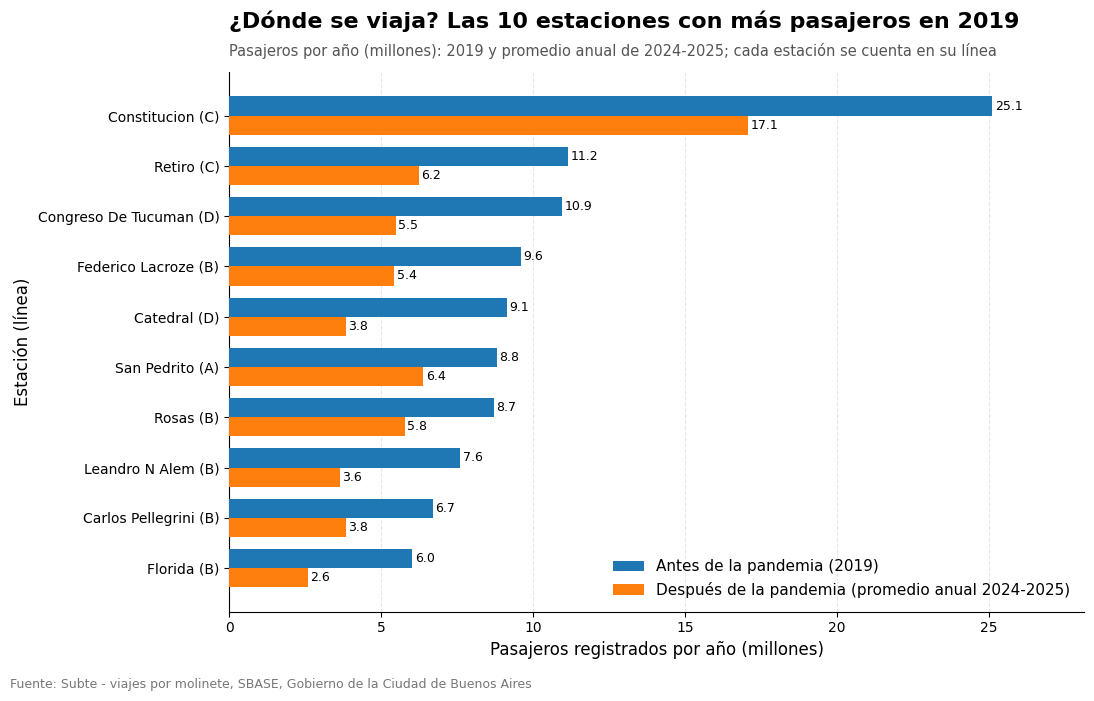

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Solo líneas A a H (sin Premetro)
lineas = ["LineaA", "LineaB", "LineaC", "LineaD", "LineaE", "LineaH"]
df_sub = df[df["linea"].isin(lineas)]

antes = df_sub[df_sub["anio"] == 2019]
despues = df_sub[df_sub["anio"].isin([2024, 2025])]

# Pasajeros por estación (cada estación dentro de su línea), en millones:
# total de 2019 y promedio anual de 2024-2025
est_antes = antes.groupby(["linea", "estacion"])["total"].sum() / 1_000_000
est_despues = despues.groupby(["linea", "estacion"])["total"].sum() / 2 / 1_000_000

# Las 10 estaciones con más pasajeros en 2019
top = est_antes.sort_values(ascending=False).head(10)
tabla = pd.DataFrame({
    "2019": top,
    "2024-2025": est_despues.reindex(top.index)
})

# Etiquetas: nombre de la estación y letra de la línea
etiquetas = [f"{est.title()} ({lin.replace('Linea', '')})" for lin, est in tabla.index]

azul = "#1f77b4"
naranja = "#ff7f0e"
y = np.arange(len(tabla))
alto = 0.38

fig, ax = plt.subplots(figsize=(11, 7))

b1 = ax.barh(y - alto / 2, tabla["2019"], alto, color=azul,
             label="Antes de la pandemia (2019)", zorder=3)
b2 = ax.barh(y + alto / 2, tabla["2024-2025"], alto, color=naranja,
             label="Después de la pandemia (promedio anual 2024-2025)", zorder=3)

# Valores al final de cada barra
for barras in (b1, b2):
    for barra in barras:
        ax.text(barra.get_width() + 0.08, barra.get_y() + barra.get_height() / 2,
                f"{barra.get_width():.1f}", va="center", fontsize=9)

ax.set_yticks(y)
ax.set_yticklabels(etiquetas)
ax.invert_yaxis()  # la estación con más pasajeros arriba

ax.set_title("¿Dónde se viaja? Las 10 estaciones con más pasajeros en 2019",
             fontsize=16, fontweight="bold", loc="left", pad=32)
ax.text(0, 1.03,
        "Pasajeros por año (millones): 2019 y promedio anual de 2024-2025; cada estación se cuenta en su línea",
        transform=ax.transAxes, fontsize=10.5, color="#555555")

ax.set_xlabel("Pasajeros registrados por año (millones)", fontsize=12)
ax.set_ylabel("Estación (línea)", fontsize=12)
ax.set_xlim(0, tabla.max().max() * 1.12)
ax.grid(axis="x", linestyle="--", alpha=0.3, zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, fontsize=11, loc="lower right")

fig.text(0.01, 0.01,
         "Fuente: Subte - viajes por molinete, SBASE, Gobierno de la Ciudad de Buenos Aires",
         fontsize=9, color="#777777")

plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig("figuras_estaciones.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Tabla de apoyo: valores citados en la interpretación
tabla_est = tabla.copy()
tabla_est["% del nivel de 2019"] = tabla_est["2024-2025"] / tabla_est["2019"] * 100
tabla_est["Puesto en 2024-2025"] = est_despues.rank(ascending=False, method="min").reindex(tabla_est.index)
print(tabla_est.round(1))

print("\n10 estaciones con más pasajeros en 2024-2025 (millones):")
print(est_despues.sort_values(ascending=False).head(10).round(1))

# Concentración: qué parte del total viaja en esas 10 estaciones
conc_antes = est_antes.sort_values(ascending=False).head(10).sum() / est_antes.sum() * 100
conc_despues = est_despues.sort_values(ascending=False).head(10).sum() / est_despues.sum() * 100
print(f"\nLas 10 principales concentran el {conc_antes:.1f} % de los pasajeros en 2019 "
      f"y el {conc_despues:.1f} % en 2024-2025")
print(f"Cantidad de estaciones con datos: {len(est_antes)} en 2019 y {len(est_despues)} en 2024-2025")

# Recuperación de las estaciones con al menos 1 millón de pasajeros en 2019
grandes = est_antes[est_antes >= 1].index
rec = (est_despues.reindex(grandes) / est_antes[grandes] * 100).sort_values()
print("\nMenor recuperación (% del nivel de 2019):")
print(rec.head(5).round(1))
print("\nMayor recuperación (% del nivel de 2019):")
print(rec.tail(5).round(1))

                            2019  2024-2025  % del nivel de 2019  \
linea  estacion                                                    
LineaC CONSTITUCION         25.1       17.1                 68.0   
       RETIRO               11.2        6.2                 55.9   
LineaD CONGRESO DE TUCUMAN  10.9        5.5                 50.0   
LineaB FEDERICO LACROZE      9.6        5.4                 56.6   
LineaD CATEDRAL              9.1        3.8                 42.0   
LineaA SAN PEDRITO           8.8        6.4                 72.6   
LineaB ROSAS                 8.7        5.8                 66.3   
       LEANDRO N ALEM        7.6        3.6                 47.9   
       CARLOS PELLEGRINI     6.7        3.8                 57.3   
       FLORIDA               6.0        2.6                 43.1   

                            Puesto en 2024-2025  
linea  estacion                                  
LineaC CONSTITUCION                         1.0  
       RETIRO                    

##  Controles de calidad de los nombres de estaciones

Esta celda revisa dos errores de los datos originales que aparecieron al analizar las estaciones y verifica que no afecten los resultados:

1. **Nombres inválidos.** Cuenta las filas y los pasajeros de `#N/D` (el error "no disponible" de Excel, que no es una estación) y de `COCHEPM`. `#N/D` aparece en 7 filas de la línea H, con 9 pasajeros en total. `COCHEPM` pertenece a la línea Premetro (PM), que se excluye de todos los análisis.
2. **Loria fuera de la línea A.** Esta estación pertenece a la línea A, pero el 22 de enero de 2025 a las 22 h figura también en las líneas B, C, D, E y H (10 filas, 80 pasajeros en total). La celda muestra cuántas filas y pasajeros hay en cada línea y en qué fecha ocurrió.

En ambos casos las cantidades son insignificantes frente a los más de 200 millones de pasajeros por año, por lo que no se eliminaron los registros y no afectan los resultados.

In [ ]:
# Chequeos de calidad de los nombres de estaciones

# 1) Nombres inválidos
sub = df[df["estacion"].isin(["#N/D", "COCHEPM"])]
print(sub.groupby(["anio", "linea", "estacion"])["total"].agg(["size", "sum"]))

# 2) Loria registrada en líneas que no son la A
loria = df[(df["estacion"] == "LORIA") & (df["linea"] != "LineaA")]
print("\nLoria fuera de la línea A:")
print(loria.groupby(["anio", "linea"])["total"].agg(filas="size", pasajeros="sum"))
print("Fechas:", sorted(loria["fecha"].dt.date.astype(str).unique()))

                       size     sum
anio linea   estacion              
2025 LineaPM COCHEPM    957   43880
2026 LineaPM COCHEPM   2626  757844

Loria fuera de la línea A:
             filas  pasajeros
anio linea                   
2025 LineaB      2         33
     LineaC      2          3
     LineaD      2         14
     LineaE      2         12
     LineaH      2         18
Fechas: ['2025-01-22']


### ***Interpretación***

La estación Constitución (línea C) es la más usada en ambos períodos y con mucha ventaja: 25,1 millones de pasajeros en 2019 y 17,1 millones por año en 2024-2025, más del doble que la segunda de 2019 (Retiro, línea C, con 11,2 millones) y más de dos veces y media la segunda de 2024-2025 (San Pedrito, línea A, con 6,4 millones). Las 10 estaciones principales concentran una parte casi idéntica del total en ambos períodos (30,4 % en 2019 y 30,0 % en 2024-2025), por lo que la demanda no se volvió más concentrada ni más dispersa.

Todas las estaciones del gráfico perdieron pasajeros, pero no por igual. Su recuperación va de 42,0 % (Catedral, línea D) a 72,6 % (San Pedrito, línea A), con un sistema que recuperó 59,7 %. Las que más recuperaron son San Pedrito (72,6 %), Constitución (68,0 %) y Rosas (línea B, 66,3 %), y las que menos, Catedral (42,0 %), Florida (línea B, 43,1 %), Leandro N. Alem (línea B, 47,9 %) y Congreso de Tucumán (línea D, 50,0 %). Por eso cambió el ranking: San Pedrito pasó del 6.° al 2.° puesto, Rosas del 7.° al 4.°, mientras que Florida cayó del 10.° al 26.° y Plaza de Mayo (línea A) entró al grupo de las 10 principales.

Entre las estaciones con al menos 1 millón de pasajeros en 2019, las diferencias de recuperación coinciden en buena medida con las diferencias entre líneas. Tres de las cinco estaciones que menos recuperaron están en la línea D (9 de Julio con 31,6 %, Agüero con 39,1 % y Catedral con 42,0 %), que es la línea con menor recuperación del sistema, y las otras dos son General San Martín (línea C, 41,1 %) y Florida (línea B, 43,1 %). Varias de ellas (9 de Julio, Catedral, General San Martín y Florida) están en la zona céntrica de la ciudad, donde se concentran las oficinas, y una explicación posible es que hayan sufrido más el trabajo remoto o híbrido, pero con estos datos no se puede comprobar ni separar del efecto de la línea. En el otro extremo, las cuatro estaciones comparables con mayor recuperación pertenecen a la línea E (Plaza de los Virreyes con 83,0 %, Independencia con 86,8 %, José María Moreno con 88,4 % y Boedo con 89,1 %). Correo Central (línea E) llega a 134,6 %, pero no es comparable: esa estación se inauguró el 3 de junio de 2019, por lo que ese año solo tuvo siete meses de datos.

En el contexto de la pregunta del trabajo, esto significa que *dónde* se viaja cambió de forma moderada: el subte sigue concentrado en las mismas estaciones, con Constitución muy por encima del resto, y las diferencias de recuperación entre estaciones siguen en gran parte el patrón de las líneas (más pérdida en la D, menos en la E).

**Cómo leer este gráfico:**
- Compara **cantidades de pasajeros** por año, no proporciones. El valor de 2024-2025 es el promedio de dos años, y 2025 tiene la incertidumbre de los otros medios de pago desde diciembre de 2024.
- Solo muestra las 10 estaciones más usadas en 2019, así que no representa a toda la red. Las recuperaciones citadas corresponden a estaciones con al menos 1 millón de pasajeros en 2019.
- Cada estación se cuenta dentro de su línea, por lo que las estaciones de combinación aparecen por separado.
- Las estaciones inauguradas en 2019 (Correo Central, Catalinas y Retiro de la línea E, desde el 3 de junio de 2019) no son comparables con 2024-2025, porque en 2019 solo tuvieron siete meses de datos.
- En 2024-2025 figuran 96 combinaciones de línea y estación, contra 90 en 2019. La diferencia no corresponde a estaciones nuevas, sino a registros erróneos de los datos originales (ver sección de controles de calidad, que detalla Loria y el valor inválido de la línea H).
- Agüero (línea D) tiene solo 7 días con datos en enero de 2024 y ninguno en febrero de 2024 ni de septiembre a diciembre de 2025, por lo que su recuperación está subestimada.
- Se excluyó el Premetro (PM), y las variables cuentan ingresos por los molinetes, no personas distintas.